# Temperature at the algorithm-deciding token (claims K1 and HR)

**Question: is temperature the "creativity knob"?** A code model picks *which algorithm* to write at one or two
generated tokens. Two examples:

- Connected components on Qwen3-8B: after ``` ```python\ndef solve(n, edges):\n   ```, the token ` parent` (0.94) leads to
  union-find, and ` def` (0.06) is followed by ` find` (97%), ` dfs` (3%) or ` bfs` (1e-5).
- Valid anagram: ` return` leads to sort-and-compare, and ` count` leads to a counting array.

This experiment applies temperature **only at that decision token**: T = d over its 20 most probable candidates, and
T = 1 everywhere else. The dose d is fixed **in advance**, from two things: the token's teacher-forced logits, and a
*token map* (10 forced T = 1 continuations of each candidate, labelled by algorithm and run against hidden tests).
The fork dose is compared with the standard knobs:

- global temperature 1.3 / 1.6 / 2.0 with top-p 0.95;
- min-p 0.1 at T 3.0;
- EDT-style (entropy-triggered) and AdapT-style (code-block start) temperature;
- the same dose at the highest-entropy position or at a random position (placebos);
- class-uniform forcing of the decision token.

Every arm reuses the same 50 common-random-number (CRN) slot streams per unit (5 prompt templates x 10 streams), so
the arms can be compared slot by slot. Every prediction was hash-committed before the samples it predicts.

**Original run:** bf16 Qwen3-8B (rev `b968826d`, thinking off) on seven coding units and bf16 Gemma-3-4b-it on a
grid task, on one NVIDIA L4 (2.8 GPU-hours).

**What this notebook runs.** The generation stages need Qwen3-8B on a GPU with at least 20 GB and cannot run here.
Everything after generation is CPU code, and the artifact ships every generated program with its label. This notebook
re-runs those original CPU stages, with the code as written, on two units of the `k1_cells` dataset (2 units x 50 slots =
100 examples):

| unit | task | T = 1 twin | role |
|---|---|---|---|
| **T10** | connected components | union-find 50/50 | *collapsed*: the headline test |
| **B6** | valid anagram | sort 40 / fixed 26-slot array 8 / hash map 2 | *mixed*: the alternative is already in play |

The stages are:

1. COMMIT #1: the dose table and composed predictions (`dose8.py`, `predict8.py`).
2. The K1 cells and verdicts (`analysis_k1.py`).
3. The COMMIT #3 amendment (`amend8.py`, `amend_analysis8.py`).
4. The hidden-repertoire (HR) branches (`hr8.py`).
5. Figures F1-F5, F7 and F8 (`figures8.py`), including the activation geometry.
6. A final check that the recomputed numbers equal the shipped ones.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (the original modules log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas: pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/cfg8.py, units8.py, predict8.py, dose8.py, analysis_k1.py, hr8.py, figures8.py
import glob
import hashlib
import io
import keyword
import json
import math
import os
import re
import resource
import tokenize
from collections import Counter, defaultdict
from datetime import datetime, timezone
from functools import lru_cache
from typing import Any, Iterable

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# notebook additions: decoding the shipped hidden states, module-style namespaces, inline figures, result tables
import base64
import warnings
import zlib
from types import SimpleNamespace

import pandas as pd
from IPython.display import display

# matplotlib's default font has no glyph for one decision-token string drawn in F4 (the token '\u7236');
# silence that one warning (the character is drawn as an empty box)
warnings.filterwarnings("ignore", message=r"Glyph \d+ .*missing from font")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-39/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            remote = json.loads(response.read().decode())
        # an earlier demo build published a differently structured file at this URL: use the remote copy only if it
        # has this notebook's layout
        if isinstance(remote, dict) and {"units", "examples", "reference_results"} <= remote.keys():
            return remote
        print("GitHub data has a different layout (an older demo build), using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print("examples:", len(data["examples"]), "| units:", data["metadata"]["units"])
ex = data["examples"][0]
print("example 0:", ex["input"])
print("  twin outcome:", ex["output"], "| arms at this slot:", sorted(ex["rows"]))

GitHub data has a different layout (an older demo build), using local mini_demo_data.json
Temperature at the algorithm-deciding token: demo subset (units T10 and B6)
examples: 100 | units: ['T10', 'B6']
example 0: unit T10 (connected components, model qwen); prompt template W1; CRN slot 0 (stream key ['T10', 'W1', 0])
  twin outcome: union_find|pass | arms at this slot: ['A0', 'A1', 'A10', 'A10f', 'A11', 'A2', 'A3g', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A9f']


## Configuration

These are all the tunable parameters of the CPU stages. The bootstrap and noise-ceiling counts set how precise the
p-values and the MAE noise ceiling are. Everything else (the dose grid, the top-20 restriction, the thresholds) is part
of the committed design and stays in the `cfg8` cell below. With the original counts, the analysis takes well under a
minute. With smaller counts the notebook still runs, but the bootstrap rows of the final check stop matching the
shipped numbers.

In [5]:
DEMO_UNITS = ["T10", "B6"]          # units shipped in mini_demo_data.json (original run: T10, T1, B3, A3, B6, T2, T03 on
                                    # Qwen3-8B and G on Gemma-3-4b-it)
N_BOOT = 2000                       # paired slot-bootstrap replicates, K1(b) and the amendment      (original: 2000)
NOISE_DRAWS = 10_000                # multinomial draws, MAE noise ceiling over all located cells     (original: 10_000)
NOISE_DRAWS_UNIT = 4000             # the same per unit                                                (original: 4000)
F2_RESAMPLES = 200                  # slot resamples behind each F2 quality-diversity ellipse          (original: 200)
WORKDIR = Path("k1_demo_artifact")  # the shipped rows are written here in the artifact's own folder layout

## 1. The pipeline (`method.py`)

`method.py` is the artifact's entry point. It chains 15 stages, each run as a subprocess.

- **GPU stages** generate programs (one model per process): `s0` twins and GPU tests, `s2` token maps, `s1` blind
  locator, `s3` arms, `s4` HR branches, `s3x` amendment arms.
- **CPU stages** build the committed predictions and analyse the rows.
- **Hash commits** (COMMIT #0, #1, #1b, #2, #3; `src/commit8.py`) chain the sha256 of each prediction file before the
  samples it predicts. They are recorded in the artifact's `commitments.log` and are not recreated here.

The cell defines the same `STEPS` / `ORDER` and the original `main()`, which is not called here. It then prints which
stages this notebook re-runs from the shipped rows.

In [6]:
ROOT = WORKDIR.resolve()            # notebook: the demo folder (originally the artifact folder)
PY = str(ROOT / ".venv" / "bin" / "python")
QWEN_UNITS = "T10,B3,T1,A3,B6"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(parents=True, exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STEPS: dict[str, list[list[str]]] = {
    "vendor": [[PY, "src/vendor_inputs.py"]],
    "prompts": [["bash", "scripts/build_gemma_prompts.sh"]],
    "cputests": [[PY, "src/tests8.py", "cpu"]],
    "commit0": [[PY, "src/protocol8.py"],
                [PY, "src/commit8.py", "commit", "COMMIT0_protocol", "predictions/protocol.json", "src/cfg8.py",
                 "src/engine8.py", "src/predict8.py", "src/units8.py", "src/gpu8.py", "src/stages8.py"]],
    "s0": [[PY, "src/gpu8.py", "qwen", "s0"], [PY, "src/gpu8.py", "gemma", "s0"]],
    "gputests": [[PY, "src/stage0_report.py"], [PY, "src/tests8.py", "gpu"]],
    "s2": [[PY, "src/gpu8.py", "qwen", "s2", "--units", QWEN_UNITS], [PY, "src/gpu8.py", "gemma", "s2"]],
    "commit1": [[PY, "src/make_commits.py", "c1"]],
    "commit2": [[PY, "src/make_commits.py", "c2"]],
    "s3": [[PY, "src/gpu8.py", "gemma", "s3,s4"], [PY, "src/gpu8.py", "qwen", "s3,s4", "--units", "T10,B3"],
           [PY, "src/gpu8.py", "qwen", "s3", "--units", "B6,T2,T03,T1,A3"]],
    "s1": [[PY, "src/gpu8.py", "qwen", "s1", "--units", "T10,B3"]],
    "s4": [[PY, "src/gpu8.py", "qwen", "s4", "--units", "B6,A3"], [PY, "src/gpu8.py", "qwen", "s3", "--units", "A3"]],
    "commit3": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/amend8.py"]],
    "s3x": [[PY, "src/gpu8.py", "qwen", "s3x", "--units", "T10"], [PY, "src/gpu8.py", "gemma", "s3x", "--units", "G"]],
    "analyse": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/stage0_report.py"], [PY, "src/analysis_k1.py"],
                [PY, "src/amend_analysis8.py"], [PY, "src/hr8.py"], [PY, "src/locator8.py"],
                [PY, "src/novelty8.py", "index"], [PY, "src/novelty8.py", "audit"], [PY, "src/report8.py"],
                [PY, "src/finalize8.py"]],
}
ORDER = ["vendor", "prompts", "cputests", "commit0", "s0", "gputests", "s2", "commit1", "commit2", "s1", "s3", "s4",
         "commit3", "s3x", "analyse"]


@logger.catch(reraise=True)
def main() -> None:
    req = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if req == "all" else req.split(",")
    labeller = None
    if any(s in ("s0", "s2", "s3", "s4", "s1") for s in stages):
        labeller = subprocess.Popen([PY, "src/label_daemon.py"], cwd=ROOT)
        logger.info(f"label daemon pid {labeller.pid}")
    try:
        for st in stages:
            for cmd in STEPS[st]:
                t0 = time.time()
                logger.info(f"[{st}] {' '.join(cmd[1:])}")
                r = subprocess.run(cmd, cwd=ROOT)
                if r.returncode != 0:
                    logger.error(f"[{st}] failed with exit code {r.returncode}")
                    raise SystemExit(r.returncode)
                logger.info(f"[{st}] done in {time.time() - t0:.0f}s")
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=3600)


# The GPU stages need Qwen3-8B / Gemma-3-4b-it on a >= 20 GB GPU, so main() is not called here. Where each step's
# result comes from in this notebook:
GPU_STAGES = {"s0", "s1", "s2", "s3", "s4", "s3x"}
IN_THIS_NOTEBOOK = {"src/make_commits.py c1": "re-run: section 8 (COMMIT #1)",
                    "src/analysis_k1.py": "re-run: section 9 (K1 cells and verdicts)",
                    "src/amend8.py": "re-run: section 10 (COMMIT #3)",
                    "src/amend_analysis8.py": "re-run: section 10",
                    "src/hr8.py": "re-run: section 11 (HR)",
                    "src/finalize8.py": "its figures8.py step: re-run in section 12",
                    "src/novelty8.py adjudicate": "judge labels shipped (results/adjudicated_labels.json)"}
for st in ORDER:
    for cmd in STEPS[st]:
        c = " ".join(cmd[1:])
        where = IN_THIS_NOTEBOOK.get(c, "GPU: generated rows are shipped" if st in GPU_STAGES else "not part of the demo")
        print(f"{st:9s} {c[:60]:62s} {where}")

vendor    src/vendor_inputs.py                                           not part of the demo
prompts   scripts/build_gemma_prompts.sh                                 not part of the demo
cputests  src/tests8.py cpu                                              not part of the demo
commit0   src/protocol8.py                                               not part of the demo
commit0   src/commit8.py commit COMMIT0_protocol predictions/protocol.   not part of the demo
s0        src/gpu8.py qwen s0                                            GPU: generated rows are shipped
s0        src/gpu8.py gemma s0                                           GPU: generated rows are shipped
gputests  src/stage0_report.py                                           not part of the demo
gputests  src/tests8.py gpu                                              not part of the demo
s2        src/gpu8.py qwen s2 --units T10,B3,T1,A3,B6                    GPU: generated rows are shipped
s2        src/gpu8.py gemma

## 2. Constants and utilities (`src/cfg8.py`)

The conventions, inherited from iterations 5-7:

- **Unit.** A UNIT is (model, task, 5 prompt templates W1-W5, 10 CRN slots per template), so it has 50 slots. Slot `s`
  uses template `W{s // 10 + 1}`.
- **Uniform streams.** Each slot owns one uniform stream (PCG64 of `stable_seed(ukey)`), with one uniform per
  generated token. Every arm reuses it, which is what makes per-slot flips between arms exact.
- **Sampler.** float64 `softmax(logits / T)`, then the truncation masks, then the inverse CDF over the full vocabulary
  in token-id order.
- **Decision node and dose.** A decision node n = (opening P_n, index i_n = |P_n|). The **dose** is (T_d, top-20) at
  generated index i_n only, with T = 1 everywhere else.

`DOSE_GRID` is the temperature grid over which the composed predictions are evaluated, and `THRESH` holds every
pre-registered threshold. Only `ROOT` changes here, and the two draw counts now come from the configuration cell.

In [7]:
ROOT = WORKDIR.resolve()          # notebook: the demo folder (originally the artifact folder)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
PROMPTS_DIR = ROOT / "prompts"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, PROMPTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

COMMITS = ROOT / "commitments.log"
SAMPLES = DATA_DIR / "samples.jsonl"            # every generated program (all stages/arms), one row per program
LABELS = DATA_DIR / "labels.jsonl"              # one label row per program (keyed by sid)
CONTS = DATA_DIR / "continuations.jsonl"        # locator / token-map / HR continuations
CONT_LABELS = DATA_DIR / "continuation_labels.jsonl"
STEPLOG = DATA_DIR / "steplog.jsonl"            # per-row decision logits, entropies, decision positions
TIMING = RESULTS_DIR / "timing.jsonl"

I6_SRC = INPUTS / "iter6_exp30" / "src"
E35 = INPUTS / "exp35"
E34 = INPUTS / "exp34"
E38 = INPUTS / "exp38"

# the declared dataset dependency art_j3Rm_lr2nzR6 (full_data_out.json): published as a sibling folder of this one;
# ART_J3RM_DIR overrides it (used on the original server, where the dependency lives in another run's folder)
DEP_DIR = Path(os.environ.get("ART_J3RM_DIR") or (ROOT.parent / "art_j3Rm_lr2nzR6"))

# ------------------------------------------------------------------------------------------------ models
QWEN_ID = "Qwen/Qwen3-8B"
QWEN_REV = "b968826d9c46dd6066d109eabc6255188de91218"
GEMMA_ID = "google/gemma-3-4b-it"
GEMMA_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
QWEN_IM_END = 151645
QWEN_EOT = 151643
GEMMA_EOS = 1
GEMMA_EOT = 106
U_LEN = 1536
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
N_SLOTS = 50
PRECISION = "bf16 weights/activations; fp32 logits; float64 CDF"

# ------------------------------------------------------------------------------------------------ units
# role: located (collapsed | mixed), boundary
UNITS: dict[str, dict[str, Any]] = {
    "T10": {"model": "qwen", "role": "collapsed", "task": "connected components", "default": "union_find",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["union_find", "bfs", "dfs"]},
    "T1": {"model": "qwen", "role": "collapsed", "task": "grid path", "default": "bfs",
           "max_new": 640, "fence": "path", "batch": 32, "label": "C",
           "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                         "iddfs", "beam"]},
    "B3": {"model": "qwen", "role": "mixed", "task": "minimum spanning tree weight", "default": "kruskal",
           "a_min": "prim_heap", "max_new": 768, "fence": "bench", "batch": 32, "label": "B",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"]},
    "A3": {"model": "qwen", "role": "mixed", "task": "trapped rain water", "default": "prefix_suffix_max",
           "a_min": "two_pointers", "max_new": 640, "fence": "bench", "batch": 40, "label": "A",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"]},
    "B6": {"model": "qwen", "role": "mixed", "task": "valid anagram", "default": "sort_compare",
           "a_min": "fixed_count_array", "max_new": 384, "fence": "bench", "batch": 40, "label": "B",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array", "alphabet_count_scan"]},
    "T2": {"model": "qwen", "role": "boundary", "task": "shortest path", "default": "dijkstra",
           "max_new": 512, "fence": "path", "batch": 40, "label": "C",
           "catalogue": ["dijkstra", "bf_spfa", "bidirectional", "a_star", "dial", "floyd_warshall"]},
    "T03": {"model": "qwen", "role": "boundary", "task": "k-th smallest", "default": "full_sort",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["full_sort", "quickselect", "size_k_heap", "heapify_pop", "counting_sort"]},
    "G": {"model": "gemma", "role": "mixed", "task": "grid path (Gemma-3-4b-it)", "default": "dfs", "a_min": "bfs",
          "max_new": 1024, "fence": "gemma", "batch": 25, "label": "C", "label_task": "T1",
          "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                        "iddfs", "beam"]},
}
LOCATED = ("T10", "T1", "B3", "A3", "B6", "G")
BOUNDARY = ("T2", "T03")
QWEN_UNITS = ("T10", "T1", "B3", "A3", "B6", "T2", "T03")


def label_task(unit: str) -> str:
    return UNITS[unit].get("label_task", unit)


def slot_template(s: int) -> str:
    return TEMPLATES[s // 10]


def slot_ukey(unit: str, s: int) -> tuple:
    w, j = slot_template(s), s % 10
    if unit in ("T10", "T1", "T2", "T03"):
        return (unit, w, j)
    if unit in ("B3", "A3", "B6"):
        return ("iter7T", unit, w, 20 + j)
    if unit == "G":
        return ("iter7GG3", "T1", w, j)
    raise KeyError(unit)


# ------------------------------------------------------------------------------------------------ design
DOSE_GRID = [1.0 + 0.25 * i for i in range(13)] + [float(x) for x in range(5, 31)] + [40.0, 60.0, 100.0]
TOPK_DOSE = 20
GLOBAL_ARMS = {"A1": 1.3, "A2": 1.6, "A3g": 2.0}       # with top-p 0.95 at every position
TOP_P_GLOBAL = 0.95
MINP = {"T": 3.0, "min_p": 0.1}
EDT = {"T_hi": 2.0, "q": 90}
ADAPT = {"T_hi": 2.0}
ENTROPY_STEPS = 96                                    # T = 1 entropy logged for generated steps 1..96
ENTROPY_WINDOW = 64                                   # entropy-max / random-window positions drawn in 1..64
WINDOW_BOUNDARY = 16
SEED_RANDOM_WINDOW = 8_800_000
SEED_CLASS_UNIFORM = 9_900_000
SEED_LOCATOR = 7_700_000
SEED_HR = 6_600_000
K_MAP = 10                                            # continuations per top-20 token in the token maps
K_HR = 5
HR_RANKS = 64
COMMITTAL = 0.8
PSEUDO = 0.5
# N_BOOT = 2000                    (notebook: set in the configuration cell)
BOOT_SEED = 20261023
# NOISE_DRAWS = 10_000             (notebook: set in the configuration cell)
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 1.5
GPU_CAP_H = 3.3

THRESH = {
    "mae_max": 0.10, "mae_units_frac": 0.80, "hill_min": 1.8, "hill_comp_max": 1.15, "pass_cost_max": 0.05,
    "reversion_max": 0.10, "entropy_below_q90_frac": 0.90, "boundary_move_max": 0.10, "boundary_pass_min": 0.5,
    "g_pass_cost_tol": 0.10, "disconfirm_share": 0.10, "disconfirm_cost": 0.10, "disconfirm_reversion": 0.30,
    "engine_agree": 0.95, "hill_depth": 25, "mixed_hill_units": 4, "d1_target_tol": 0.10, "attempted_d1": 0.20,
    "attempted_d2": 0.40, "minority_d1": 0.5, "t1_valid_k": 5, "t1_valid_pass": 0.7, "adjudicate_other": 0.20,
}


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """sha256 of the '|'-joined str() of the parts, mod 2^63 (exp8/exp17/exp29/exp35 convention)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def model_path(model_id: str, revision: str) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots" / revision
        if snap.exists():
            return str(snap)
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, revision=revision)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def dumps(obj: Any) -> str:
    return json.dumps(obj, default=_json_default)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text[:200]}")


def log_timing(tag: str, **kw: Any) -> None:
    append_jsonl(TIMING, [{"tag": tag, "utc": utc_now(), **kw}])

## 3. Decision nodes (`src/units8.py`)

The decision nodes were pre-registered from iteration 7 and re-measured here:

- **T10 `n10`:** the 10-token opening ``` ```python\ndef solve(n, edges):\n   ```, so the decision is at generated index 10.
- **T10 `n11`:** `n10` plus ` def`, at index 11. This is the second decision, ` find` vs ` dfs` vs ` bfs`.
- **B6 `c0`:** the 23-token opening that ends after `if len(s) != len(t):\n        return False\n   `.

The GPU-stage helpers are omitted: prompt token ids, the partial-program classifiers of the blind locator, and the
engine check. The other modules call these functions as `U8.<name>`.

In [8]:
T10_N10 = [73594, 12669, 198, 750, 11625, 1445, 11, 12822, 982, 262]
T10_DEF = 707
T1_OPEN = [73594, 12669, 198]


@lru_cache(maxsize=1)
def _forks35() -> dict[str, Any]:
    return read_json(E35 / "results" / "forks.json")


@lru_cache(maxsize=1)
def gemma_fork() -> dict[str, Any]:
    return read_json(E38 / "inputs" / "iter6_gemma" / "results" / "fork.json")


def nodes(unit: str) -> list[dict[str, Any]]:
    """Primary decision nodes of a unit: [{'id', 'opening', 'pos'}] (pos = |opening| = generated decision index)."""
    if unit == "T10":
        return [{"id": "n10", "opening": list(T10_N10), "pos": 10}]
    if unit == "T1":
        return [{"id": "n3", "opening": list(T1_OPEN), "pos": 3}]
    if unit in ("B3", "A3", "B6"):
        out = []
        for c in _forks35()[unit]["opening"]["clusters"]:
            out.append({"id": c["id"], "opening": [int(t) for t in c["O"]], "pos": len(c["O"]),
                        "cov_exp35": c.get("cov")})
        return out
    if unit == "G":
        cs = [int(t) for t in gemma_fork()["cstar_ids"]]
        return [{"id": "cstar", "opening": cs, "pos": len(cs)}]
    return []


def second_node(unit: str) -> dict[str, Any] | None:
    """T10's second decision: n11 = n10 + ' def' (index 11)."""
    if unit == "T10":
        return {"id": "n11", "opening": list(T10_N10) + [T10_DEF], "pos": 11, "parent": "n10", "via": T10_DEF}
    return None


# the other modules call these as U8.<name> (`import units8 as U8` in the original)
U8 = SimpleNamespace(T10_N10=T10_N10, T10_DEF=T10_DEF, T1_OPEN=T1_OPEN, nodes=nodes, second_node=second_node)
print("T10 nodes:", [(n["id"], n["pos"]) for n in U8.nodes("T10")], "+ second:", U8.second_node("T10")["id"])

T10 nodes: [('n10', 10)] + second: n11


## 4. Write the shipped rows into the artifact's folder layout

The original modules read these files:

- `data/samples.jsonl` and `data/labels.jsonl`: every program, its label and its hidden-test pass flag.
- `data/continuations.jsonl` and `data/continuation_labels.jsonl`: the token-map and HR continuations.
- `cache/nodes/*.json`: the teacher-forced top-64 logits at each decision node, per template.
- `cache/hid/*.npz`: the hidden states for F8.
- `results/adjudicated_labels.json`: labels resolved by the blind judges.
- Three small prior inputs used by `units8` and `hr8`.

This cell writes the demo subset to exactly those paths under `WORKDIR`, using the original `write_json` /
`write_jsonl`, so the code below reads them unchanged. The hidden states are shipped as zlib-compressed float16 bytes
and are written back as the same `sids` / `H` npz arrays the engine saved.

In [9]:
sample_rows, label_rows = [], []
for ex in data["examples"]:                       # one example = one CRN slot of one unit, every arm's program
    for arm, r in ex["rows"].items():
        r = dict(r)
        L = r.pop("label_row")
        sample_rows.append(r)
        label_rows.append({"sid": r["sid"], "unit": r["unit"], **L})
write_jsonl(SAMPLES, sample_rows)
write_jsonl(LABELS, label_rows)

cont_rows, cont_label_rows = [], []
forks, s4b, forced = {}, {}, []
for u, e in data["units"].items():
    for r in e["continuations"]:                  # token-map (MAP) and hidden-repertoire (HR) continuations
        r = dict(r)
        L = r.pop("label_row")
        cont_rows.append(r)
        cont_label_rows.append({"sid": r["sid"], "unit": r["unit"], **L})
    for name, info in e["node_cache"].items():    # teacher-forced top-64 logits per node and template
        write_json(CACHE_DIR / "nodes" / f"{name}.json", info)
    hs = e["hidden_states"]                       # mean final-norm state of the 16 positions from the decision token
    H = np.frombuffer(zlib.decompress(base64.b64decode(hs["data"])), dtype=np.float16).reshape(hs["shape"])
    (CACHE_DIR / "hid").mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE_DIR / "hid" / f"demo_{u}.npz", sids=np.array(hs["sids"]), H=H)
    forks.update(e["exp35_forks"] or {})
    s4b.update(e["exp35_s4b"] or {})
    forced += e["iter2_forced_programs"] or []
write_jsonl(CONTS, cont_rows)
write_jsonl(CONT_LABELS, cont_label_rows)
write_json(RESULTS_DIR / "adjudicated_labels.json", data["adjudicated_labels"])
write_json(E35 / "results" / "forks.json", forks)                            # B6's opening cluster (units8.nodes)
write_json(E35 / "results" / "s4b.json", s4b)                                # exp35 forced labels (hr8.forced_ideas)
write_jsonl(INPUTS / "iter2_exp11" / "bench" / "T10_forced_programs.jsonl", forced)

print(f"samples {len(sample_rows)} | continuations {len(cont_rows)} | adjudicated {len(data['adjudicated_labels'])}")
print("arms per unit:", {u: sorted({r['arm'] for r in sample_rows if r['unit'] == u}) for u in DEMO_UNITS})
print("hidden states:", {u: e["hidden_states"]["shape"] for u, e in data["units"].items()})

samples 1200 | continuations 1315 | adjudicated 95
arms per unit: {'T10': ['A0', 'A1', 'A10', 'A10f', 'A11', 'A2', 'A3g', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A9f'], 'B6': ['A0', 'A1', 'A10', 'A11', 'A2', 'A3g', 'A5', 'A7', 'A8', 'A9']}
hidden states: {'T10': [300, 4096], 'B6': [233, 4096]}


## 5. The committed prediction math (`src/predict8.py`)

Token-map composition, for node n with fp32 teacher-forced logits z_n per template:

- π_T(t | n) = softmax(z_n[top20] / T), restricted to the 20 highest-logit tokens.
- G(A | n, t) = P̂(A | n, t) from the token map if t is *committal* (max_A P̂ ≥ 0.8) or n has no second decision.
  Otherwise it is the two-token composition through the next decision n + t.
- F_T(A | n) = Σ_t π_T(t | n) G(A | n, t).
- P_T(A) = Σ_c w_c F_T(A | n_c) + (1 − Σ_c w_c) q_rest(A). Here w_c is the T = 1 probability of staying on opening c,
  and q_rest is the twin's label mix off the openings.

The same composition with Pfail gives the predicted pass cost, and with Prev the predicted reversion.

**Per-slot replay.** The dosed token of slot s is the inverse CDF (token-id order) of π_T(· | n) at the slot's own
uniform U[s, i_n]. A slot whose token does not change keeps the twin's label.

**Statistics.**

- Wilson / Newcombe paired intervals and the exact McNemar test.
- Correct-only **Hill-1 rarefied to 25**: the exponentiated expected Shannon entropy of the algorithm labels in a
  random 25-subset of the correct programs, so 1 means one idea.
- The MAE noise ceiling.

Only change: `mae_noise_ceiling` takes its default draw count from the configuration cell.

In [10]:
# ------------------------------------------------------------------------------------------------ distributions
def dist_topk(z: Any, T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """(token ids, probabilities) of softmax(z[topk] / T) over the k highest logits (k = 0: full vocabulary).
    z is a full logit vector, or a (ids, logits) pair of saved top logits sorted descending."""
    if isinstance(z, tuple):
        return dist_top_from_saved(z[0], z[1], T, k)
    z = np.asarray(z, dtype=np.float64)
    if k and k > 0:
        ids = np.argpartition(-z, k - 1)[:k]
    else:
        ids = np.arange(len(z))
    x = z[ids] / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    return ids, p


def dist_top_from_saved(ids: list[int], z: list[float], T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """Same from saved top-64 (ids sorted by logit, descending)."""
    ids_a = np.asarray(ids[:k], dtype=np.int64)
    x = np.asarray(z[:k], dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    return ids_a, p / p.sum()


def phat_vec(labels: list[str], classes: list[str]) -> np.ndarray:
    """Phat over classes (catalogue + 'other' + 'invalid') with pseudo-count PSEUDO per class."""
    c = np.full(len(classes), PSEUDO, dtype=np.float64)
    for l in labels:
        c[classes.index(l) if l in classes else classes.index("other")] += 1.0
    return c / c.sum()


def committal(ph: np.ndarray, classes: list[str]) -> str | None:
    """class(t) if max_A Phat(A | n, t) >= 0.8 over the catalogue algorithms (not 'other'/'invalid'), else None."""
    j = int(np.argmax(ph))
    if ph[j] >= COMMITTAL and classes[j] not in ("other", "invalid"):
        return classes[j]
    return None


def compose_node(z: np.ndarray, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, np.ndarray],
                 second: dict[int, dict[str, Any]] | None = None, k: int = 20) -> dict[str, np.ndarray]:
    """F_T(. | n) for algorithm shares, Pfail and Prev at one node and one template.
    tmap[t] = {'phat': [C], 'pfail': float, 'prev': float} for the mapped tokens; tokens of top20 without a map use
    `resid` ({'phat','pfail','prev'}). second[t] = {'z': z_{n+t}, 'tmap': ..., 'resid': ...} for non-committal t."""
    ids, p = dist_topk(z, T, k)
    C = len(resid["phat"])
    F = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off_mass = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose_node(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], None, k)
            F += pt * sub["F"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev_mass"]
            off_mass += pt * sub["off_mass"]
            continue
        m = tmap.get(t)
        if m is None:
            F += pt * resid["phat"]
            fail += pt * resid["pfail"]
            continue
        F += pt * m["phat"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off_mass += pt
            rev += pt * m["prev"]
    return {"F": F, "fail": fail, "rev_mass": rev, "off_mass": off_mass}


def compose_unit(node_data: list[dict[str, Any]], q_rest: np.ndarray, q_rest_fail: float, T: float,
                 k: int = 20) -> dict[str, Any]:
    """P_T(A) for one template: node_data = [{'w': w_c, 'z', 'tmap', 'resid', 'second'}]."""
    C = len(q_rest)
    P = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off = 0.0
    wsum = 0.0
    for nd in node_data:
        r = compose_node(nd["z"], T, nd["tmap"], nd["resid"], nd.get("second"), k)
        P += nd["w"] * r["F"]
        fail += nd["w"] * r["fail"]
        rev += nd["w"] * r["rev_mass"]
        off += nd["w"] * r["off_mass"]
        wsum += nd["w"]
    wsum = min(wsum, 1.0)
    P += (1.0 - wsum) * q_rest
    fail += (1.0 - wsum) * q_rest_fail
    return {"P": P, "fail": fail, "reversion": (rev / off) if off > 1e-12 else 0.0, "off_token_mass": off,
            "on_opening": wsum}


# ------------------------------------------------------------------------------------------------ replay
def replay_token(top_ids: list[int], top_z: list[float], u: float, T: float, k: int = 20) -> int:
    """Inverse CDF in TOKEN-ID order over the top-k at temperature T (engine order), searchsorted(left)."""
    ids = np.asarray(top_ids[:k], dtype=np.int64)
    z = np.asarray(top_z[:k], dtype=np.float64)
    o = np.argsort(ids)
    ids, z = ids[o], z[o]
    x = z / float(T)
    x = x - x.max()
    p = np.exp(x)
    cdf = np.cumsum(p)
    cdf /= cdf[-1]
    j = int(np.searchsorted(cdf, u, side="left"))
    return int(ids[min(j, len(ids) - 1)])


# ------------------------------------------------------------------------------------------------ statistics
def wilson(x: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = x / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.96) -> dict[str, float]:
    """Newcombe (1998) method 10 hybrid-score CI for p1 - p2 of paired binary outcomes.
    a = both 1, b = 1 then 0, c = 0 then 1, d = both 0; p1 = (a + b) / n, p2 = (a + c) / n."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, z)
    l2, u2 = wilson(a + c, n, z)
    diff = p1 - p2
    denom = (a + b) * (c + d) * (a + c) * (b + d)
    if denom == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > n / 2:
            num -= n / 2
        elif num >= 0:
            num = 0.0
        phi = num / math.sqrt(denom)
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0.0)), "hi": diff + math.sqrt(max(du2, 0.0))}


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":          # H1: b > c
        return float(stats.binom.sf(b - 1, n, 0.5))
    if alternative == "less":
        return float(stats.binom.cdf(b, n, 0.5))
    return float(min(1.0, 2 * min(stats.binom.cdf(min(b, c), n, 0.5), 1.0)))


def hill1_rarefied(labels: list[str], depth: int = 25) -> float | None:
    """exp(E[H]) with E[H] the exact hypergeometric expectation of the Shannon entropy (nats) of a random
    depth-subset (without replacement) of the given labels; None if fewer than depth labels."""
    N = len(labels)
    if N < depth:
        return None
    from collections import Counter
    EH = 0.0
    for _, n_i in Counter(labels).items():
        xs = np.arange(1, min(n_i, depth) + 1)
        pm = stats.hypergeom.pmf(xs, N, n_i, depth)
        q = xs / depth
        EH -= float(np.sum(pm * q * np.log(q)))
    return float(math.exp(EH))


def hill1_bruteforce(labels: list[str], depth: int) -> float:
    """Brute-force check of hill1_rarefied on small inputs (all subsets)."""
    from collections import Counter
    from itertools import combinations
    Hs = []
    for sub in combinations(range(len(labels)), depth):
        cnt = Counter(labels[i] for i in sub)
        q = np.array(list(cnt.values()), dtype=float) / depth
        Hs.append(-float(np.sum(q * np.log(q))))
    return float(math.exp(np.mean(Hs)))


def mae_noise_ceiling(pred: list[np.ndarray], n: int = 50, draws: int = NOISE_DRAWS, thr: float = 0.10,
                      seed: int = 20261023) -> float:
    """P(MAE <= thr | prediction exactly true): draw each cell's counts ~ Multinomial(n, pred_cell), MAE over all
    (cell, class) entries; pred = list of share vectors (one per cell)."""
    rng = np.random.default_rng(seed)
    ok = 0
    P = [np.clip(np.asarray(p, dtype=float), 0, None) for p in pred]
    P = [p / p.sum() for p in P]
    for _ in range(draws):
        errs = []
        for p in P:
            x = rng.multinomial(n, p) / n
            errs.extend(np.abs(x - p).tolist())
        ok += float(np.mean(errs)) <= thr
    return ok / draws


def pick_dose(curve: dict[float, float], target: float, attainable_frac: float | None = None) -> float | None:
    """Smallest grid T whose predicted value reaches target (curve: T -> value, increasing T)."""
    for T in sorted(curve):
        if curve[T] >= target - 1e-12:
            return T
    return None


# the other modules call these as PR.<name> (`import predict8 as PR` in the original)
PR = SimpleNamespace(**{k: globals()[k] for k in ["dist_topk", "dist_top_from_saved", "phat_vec", "committal", "compose_node", "compose_unit", "replay_token", "wilson", "newcombe_paired", "mcnemar_exact", "hill1_rarefied", "hill1_bruteforce", "mae_noise_ceiling", "pick_dose"]})
print("Hill-1 of 40 sort / 8 array / 2 hash (rarefied to 25):",
      round(PR.hill1_rarefied(["sort"] * 40 + ["array"] * 8 + ["hash"] * 2, 25), 3))

Hill-1 of 40 sort / 8 array / 2 hash (rarefied to 25): 1.778


## 6. Token maps (`src/dose8.py`, part 1)

At every decision node, Stage 2 forced each of the ~24 most probable tokens and continued it 10 times at T = 1. Each
program was labelled by algorithm and run against the hidden tests. `token_maps` turns these into per-token values:

- P̂(class): the plug-in frequencies, used by the composition (deviation D05);
- Pfail: the share of continuations that fail;
- Pcorrect;
- the committal class: the class with P̂ ≥ 0.8 under a pseudo-count of 0.5;
- the off-default flag and the reversion probability Prev.

`twin_rows` reads the T = 1 twin (arm A0) with its decision-token log.

In [11]:
NODE_DIR = CACHE_DIR / "nodes"
BAD = {"invalid", "no_code", "label_error", "extraction"}
LOCATED_ORDER = ("T10", "T1", "B3", "A3", "B6", "G")


# ------------------------------------------------------------------------------------------------ labels/classes
def classes_of(unit: str) -> list[str]:
    return list(UNITS[unit]["catalogue"]) + ["other", "invalid"]


def cls(unit: str, label: str | None) -> str:
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_labels() -> dict[str, dict[str, Any]]:
    """Frozen labels; rows resolved by the judge adjudication (results/adjudicated_labels.json) take that label."""
    out = {r["sid"]: r for r in read_jsonl(LABELS)}
    out.update({r["sid"]: r for r in read_jsonl(CONT_LABELS)})
    adj_p = RESULTS_DIR / "adjudicated_labels.json"
    if adj_p.exists():
        for sid, lab in read_json(adj_p).items():
            if sid in out:
                out[sid] = {**out[sid], "label": lab, "labeller_source": "adjudicated"}
    return out


def twin_rows(unit: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    out = {}
    for r in read_jsonl(SAMPLES):
        if r["unit"] == unit and r["arm"] == "A0":
            L = labels.get(r["sid"], {})
            r["label"] = L.get("label")
            r["cls"] = cls(unit, L.get("label"))
            r["passed"] = bool(L.get("passed"))
            out[r["slot"]] = r
    return out


def node_info(unit: str, node: str) -> dict[str, Any] | None:
    p = NODE_DIR / f"{unit}_{node}.json"
    return read_json(p) if p.exists() else None


def token_maps(unit: str, node: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    """Phat / Pfail / Pcorrect / Prev per mapped token at one node, from its K continuations."""
    C = classes_of(unit)
    default = UNITS[unit]["default"]
    by_tok: dict[int, list[tuple[str, bool]]] = defaultdict(list)
    for r in read_jsonl(CONTS):
        if r.get("arm") != "MAP" or r["unit"] != unit or r.get("node") != node:
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        by_tok[int(r["token"])].append((cls(unit, L.get("label")), bool(L.get("passed"))))
    out = {}
    node_classes = sorted({c for lst in by_tok.values() for c, _ in lst})
    for t, lst in by_tok.items():
        labs = [c for c, _ in lst]
        ph = np.array([sum(1 for c in labs if c == k) for k in C], dtype=float) / len(labs)   # plug-in (D05)
        ph_s = PR.phat_vec(labs, node_classes)                 # pseudo-count 0.5 over the node's observed classes
        ph_s_full = np.zeros(len(C))
        for k, v in zip(node_classes, ph_s):
            ph_s_full[C.index(k)] = v
        corr = np.zeros(len(C))
        for c, ok in lst:
            if ok:
                corr[C.index(c)] += 1
        corr = corr / max(len(lst), 1)
        com = PR.committal(ph_s_full, C)
        off = com is not None and com != default
        prev = (sum(1 for c in labs if c == default) / len(labs)) if off else 0.0
        out[t] = {"phat": ph, "phat_smoothed": ph_s_full, "pfail": 1.0 - sum(ok for _, ok in lst) / len(lst),
                  "pcorrect": corr, "n": len(lst),
                  "counts": dict(Counter(labs)), "committal": com, "off_default": off, "prev": prev}
    return out


def resid_of(tmap: dict[int, dict[str, Any]], weights: dict[int, float], C: int) -> dict[str, Any]:
    tot = sum(weights.get(t, 0.0) for t in tmap) or 1.0
    ph = sum(weights.get(t, 0.0) * m["phat"] for t, m in tmap.items()) / tot if tmap else np.full(C, 1.0 / C)
    pf = sum(weights.get(t, 0.0) * m["pfail"] for t, m in tmap.items()) / tot if tmap else 0.0
    pc = sum(weights.get(t, 0.0) * m["pcorrect"] for t, m in tmap.items()) / tot if tmap else np.zeros(C)
    return {"phat": ph, "pfail": pf, "pcorrect": pc, "prev": 0.0}


STRING_CLASS = {"T10": [(r"(?i)\bdfs|depth", "dfs"), (r"(?i)\bbfs|breadth|queue|deque", "bfs"),
                        (r"(?i)union|find|parent|disjoint|dsu|root", "union_find")]}


def string_class(unit: str, s: str) -> str | None:
    for pat, c in STRING_CLASS.get(unit, []):
        if re.search(pat, s):
            return c
    return None

## 7. Composition and per-slot replay (`src/dose8.py`, part 2)

- `compose` evaluates F_T at one node and template.
- `UnitModel.predict(T)` averages it over the five templates, weights it by the opening probability w_c, and adds the
  off-opening remainder q_rest. On T10, the index-10 token ` def` triggers the second dose at index 11, which is the
  two-token composition through `n11`.
- `slot_replay` predicts each slot's class under a dose from the slot's own uniform and its captured logits.
- `BAN` is the amendment's banned-token set. It is empty for COMMIT #1.

In [12]:
# ------------------------------------------------------------------------------------------------ composition
BAN: dict[str, set[int]] = {}        # amendment (COMMIT #3): tokens removed at a dosed node, keyed by node id


def compose(z: tuple, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, Any], C: int,
            second: dict[int, dict[str, Any]] | None = None, k: int = TOPK_DOSE,
            ban: set[int] | None = None, ban2: set[int] | None = None) -> dict[str, Any]:
    """F_T at one node and template: attempted shares, correct shares, fail mass, reversion mass, off-token mass.
    ban: tokens removed from this node's top-k (renormalised over the rest); ban2: the same at the second node."""
    ids, p = PR.dist_topk(z, T, k)
    if ban:
        keep = np.array([int(t) not in ban for t in ids.tolist()])
        if keep.any():
            ids, p = ids[keep], p[keep] / p[keep].sum()
    F = np.zeros(C)
    Fc = np.zeros(C)
    fail = rev = off = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], C, None, k, ban=ban2)
            F += pt * sub["F"]
            Fc += pt * sub["Fc"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev"]
            off += pt * sub["off"]
            continue
        m = tmap.get(t, resid)
        F += pt * m["phat"]
        Fc += pt * m["pcorrect"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off += pt
            rev += pt * m["prev"]
    return {"F": F, "Fc": Fc, "fail": fail, "rev": rev, "off": off}


class UnitModel:
    """Everything needed to predict a unit's cell at any fork dose (per template, averaged over templates)."""

    def __init__(self, unit: str, labels: dict[str, dict[str, Any]]):
        self.unit = unit
        self.C = classes_of(unit)
        self.default = UNITS[unit]["default"]
        self.twin = twin_rows(unit, labels)
        self.nodes = []
        for nd in U8.nodes(unit):
            info = node_info(unit, nd["id"])
            if info is None:
                continue
            tm = token_maps(unit, nd["id"], labels)
            self.nodes.append({"id": nd["id"], "pos": nd["pos"], "info": info, "tmap": tm})
        self.second = None
        if unit == "T10":
            info11 = node_info(unit, "n11")
            tm11 = token_maps(unit, "n11", labels) if info11 else {}
            self.second = {"info": info11, "tmap": tm11}
        # off-opening composition q_rest from the twin
        on = [s for s, r in self.twin.items() if r.get("reached_decision")]
        offs = [r for s, r in self.twin.items() if not r.get("reached_decision")]
        self.q_rest = PR.phat_vec([r["cls"] for r in offs], self.C) if offs else np.full(len(self.C), 1 / len(self.C))
        self.q_rest_fail = (1 - np.mean([r["passed"] for r in offs])) if offs else 0.0
        self.q_rest_corr = np.zeros(len(self.C))
        for r in offs:
            if r["passed"]:
                self.q_rest_corr[self.C.index(r["cls"])] += 1.0 / len(offs)
        self.n_on = len(on)

    def second_tokens(self) -> set[int]:
        """T10 index-10 tokens that trigger the index-11 dose: ' def' (n11 is pre-registered as its second decision;
        at T = 1 it is followed by ' find' 97% of the time, so its T = 1 map reads union-find) plus every
        non-committal token that has a teacher-forced index-11 distribution (mass >= 1e-4)."""
        if self.unit != "T10" or not self.nodes:
            return set()
        nd = self.nodes[0]
        out = {U8.T10_DEF}
        for t, m in nd["tmap"].items():
            if m["committal"] is None and str(t) in nd["info"].get("second_tf", {}):
                out.add(int(t))
        return out

    def _node_parts(self, nd: dict[str, Any], w: str) -> tuple[tuple, dict, dict, dict | None, float]:
        tf = nd["info"]["tf"][w]
        z = (tf["top_ids"], tf["top_z"])
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        resid = resid_of(nd["tmap"], pooled, len(self.C))
        second = None
        if self.unit == "T10" and nd["id"] == "n10" and self.second and self.second["info"]:
            second = {}
            for t, m in nd["tmap"].items():
                if t not in self.second_tokens():
                    continue
                if t == U8.T10_DEF:
                    tf11 = self.second["info"]["tf"][w]
                    p11 = {int(k): v for k, v in self.second["info"]["pooled_p20"].items()}
                    second[t] = {"z": (tf11["top_ids"], tf11["top_z"]), "tmap": self.second["tmap"],
                                 "resid": resid_of(self.second["tmap"], p11, len(self.C))}
                elif str(t) in nd["info"].get("second_tf", {}):
                    tf2 = nd["info"]["second_tf"][str(t)][w]
                    tm2 = {}
                    for t2 in tf2["top_ids"][:TOPK_DOSE]:
                        j2 = tf2["top_ids"].index(t2)
                        c2 = string_class(self.unit, tf2.get("top_str", [""] * 64)[j2] if j2 < 24 else "")
                        if c2 is not None:
                            ph = PR.phat_vec([c2] * 10, self.C)
                            tm2[int(t2)] = {"phat": ph, "pfail": m["pfail"], "pcorrect": ph * (1 - m["pfail"]),
                                            "off_default": c2 != self.default, "prev": 0.0, "committal": c2}
                    second[t] = {"z": (tf2["top_ids"], tf2["top_z"]), "tmap": tm2,
                                 "resid": {"phat": m["phat"], "pfail": m["pfail"], "pcorrect": m["pcorrect"],
                                           "prev": 0.0}}
        w_c = math.exp(tf["path_logprob"])
        return z, nd["tmap"], resid, second, w_c

    def predict(self, T: float) -> dict[str, Any]:
        C = len(self.C)
        P = np.zeros(C)
        Pc = np.zeros(C)
        fail = rev = off = on = 0.0
        for w in TEMPLATES:
            Pw = np.zeros(C)
            Pcw = np.zeros(C)
            fw = rw = ow = ws = 0.0
            for nd in self.nodes:
                z, tm, resid, second, w_c = self._node_parts(nd, w)
                r = compose(z, T, tm, resid, C, second, ban=BAN.get(f"{self.unit}:{nd['id']}"),
                            ban2=BAN.get(f"{self.unit}:n11"))
                Pw += w_c * r["F"]
                Pcw += w_c * r["Fc"]
                fw += w_c * r["fail"]
                rw += w_c * r["rev"]
                ow += w_c * r["off"]
                ws += w_c
            ws = min(ws, 1.0)
            Pw += (1 - ws) * self.q_rest
            Pcw += (1 - ws) * self.q_rest_corr
            fw += (1 - ws) * self.q_rest_fail
            P += Pw / len(TEMPLATES)
            Pc += Pcw / len(TEMPLATES)
            fail += fw / len(TEMPLATES)
            rev += rw / len(TEMPLATES)
            off += ow / len(TEMPLATES)
            on += ws / len(TEMPLATES)
        return {"P": P, "Pc": Pc, "fail": fail, "reversion": rev / off if off > 1e-12 else 0.0, "off_mass": off,
                "on_opening": on}

    def off_default_share(self, P: np.ndarray) -> float:
        return float(sum(P[i] for i, c in enumerate(self.C) if c not in (self.default, "other", "invalid")))

    # ---------------------------------------------------------------- per-slot replay
    def slot_replay(self, s: int, T: float, k: int = TOPK_DOSE) -> dict[str, Any]:
        """Predicted class distribution of slot s under a fork dose T (identity property for unchanged tokens)."""
        r = self.twin[s]
        Cn = len(self.C)
        onehot = np.zeros(Cn)
        onehot[self.C.index(r["cls"])] = 1.0
        if not r.get("reached_decision") or r.get("dec_top_ids") is None:
            return {"dist": onehot, "changed": False, "token": None, "dosed": False}
        u = u_stream(*slot_ukey(self.unit, s))
        dpos = r["decision_pos"]
        nd_id = U8.nodes(self.unit)[r["decision_node"]]["id"]
        bn = BAN.get(f"{self.unit}:{nd_id}")
        if bn:
            ids_k = [t for t in r["dec_top_ids"][:k] if t not in bn]
            zs = [z for t, z in zip(r["dec_top_ids"][:k], r["dec_top_z"][:k]) if t not in bn]
            t_new = PR.replay_token(ids_k, zs, float(u[dpos]), T, len(ids_k)) if ids_k else r["decision_token"]
        else:
            t_new = PR.replay_token(r["dec_top_ids"], r["dec_top_z"], float(u[dpos]), T, k)
        if t_new == r["decision_token"]:
            return {"dist": onehot, "changed": False, "token": t_new, "dosed": True, "pass": r["passed"]}
        nd = next((n for n in self.nodes if n["id"] == U8.nodes(self.unit)[r["decision_node"]]["id"]), None)
        if nd is None:
            return {"dist": onehot, "changed": True, "token": t_new, "dosed": True}
        m = nd["tmap"].get(t_new)
        if m is None:
            m = resid_of(nd["tmap"], {int(a): b for a, b in nd["info"]["pooled_p20"].items()}, Cn)
            m["committal"] = None
        dist = m["phat"]
        if self.unit == "T10" and t_new in self.second_tokens() and self.second and self.second["info"]:
            # second dose at index 11: composition over index-11 tokens under this slot's template
            _, _, _, second, _ = self._node_parts(nd, slot_template(s))
            if second and t_new in second:
                sub = compose(second[t_new]["z"], T, second[t_new]["tmap"], second[t_new]["resid"], Cn, None, k,
                              ban=BAN.get(f"{self.unit}:n11"))
                dist = sub["F"]
        return {"dist": np.asarray(dist), "changed": True, "token": t_new, "dosed": True,
                "pfail": float(m.get("pfail", 0.0))}

    def replay_cell(self, T: float) -> dict[str, Any]:
        dists, changed = [], 0
        per = {}
        for s in sorted(self.twin):
            rr = self.slot_replay(s, T)
            dists.append(rr["dist"])
            changed += int(rr["changed"])
            per[s] = {"token": rr["token"], "changed": rr["changed"],
                      "pred": self.C[int(np.argmax(rr["dist"]))], "dist": np.round(rr["dist"], 4).tolist()}
        return {"P": np.mean(dists, 0) if dists else np.zeros(len(self.C)), "n_changed": changed, "per_slot": per}

## 8. Dose table and COMMIT #1 (`src/dose8.py`, part 3)

The dose rules were committed before any Stage 3 sample:

- **Collapsed unit:** d1 and d2 reach 0.20 and 0.40 attempted off-default share if that is attainable. Otherwise
  d1 = half the attainable maximum and d2 = 0.95 x the maximum.
- **Mixed unit:** d1 reaches a minority share of 0.5, or the midpoint between the twin and the maximum.
  d2 = 0.95 x the maximum.

`build_commit1` also fixes:

- the placebo positions: the entropy-max position j* and a random window;
- the class-uniform forcing draws;
- the entropy check (c): whether the twin's decision-token entropy falls below the 90th percentile of its per-token
  entropies;
- the MAE noise ceiling.

Only change: the noise-ceiling draw counts come from the configuration cell.

In [13]:
# ------------------------------------------------------------------------------------------------ doses
def dose_table(M: UnitModel, role: str) -> dict[str, Any]:
    curve = {T: M.predict(T) for T in DOSE_GRID}
    share = {T: M.off_default_share(curve[T]["P"]) for T in DOSE_GRID}
    mx = max(share.values())          # attainable maximum over the grid (the curve is not monotone in T)
    T_mx = max(share, key=lambda T: share[T])
    if role == "collapsed":
        t1, t2 = THRESH["attempted_d1"], THRESH["attempted_d2"]
        if mx >= t2:
            d1, d2 = PR.pick_dose(share, t1), PR.pick_dose(share, t2)
            tgt1 = t1
            rule = "targets 0.20 / 0.40 attempted off-default"
        else:
            d2 = PR.pick_dose(share, 0.95 * mx)
            d1 = PR.pick_dose(share, 0.5 * mx) if mx < t1 else PR.pick_dose(share, t1)
            tgt1 = 0.5 * mx if mx < t1 else t1
            rule = f"attainable max {mx:.3f} < 0.40: d2 = 0.95 x max, d1 = " + ("half of max" if mx < t1 else "0.20")
    else:
        tw = share[1.0]
        if mx >= THRESH["minority_d1"]:
            d1 = PR.pick_dose(share, THRESH["minority_d1"])
            tgt1 = THRESH["minority_d1"]
            rule = "d1: minority share 0.5"
        else:
            d1 = PR.pick_dose(share, (tw + mx) / 2)
            tgt1 = (tw + mx) / 2
            rule = f"0.5 unattainable (max {mx:.3f}): d1 at midpoint of twin {tw:.3f} and max"
        d2 = PR.pick_dose(share, 0.95 * mx) if mx > tw else DOSE_GRID[-1]
    d1 = d1 or DOSE_GRID[-1]
    d2 = d2 or DOSE_GRID[-1]
    if d2 < d1:
        d1, d2 = d2, d1
    return {"d1": d1, "d2": d2, "rule": rule, "target_share_d1": tgt1, "T_at_max": T_mx, "share_curve": share, "max_share": mx, "twin_pred_share": share[1.0],
            "curve": {T: {"P": curve[T]["P"].tolist(), "Pc": curve[T]["Pc"].tolist(), "fail": curve[T]["fail"],
                          "reversion": curve[T]["reversion"], "on_opening": curve[T]["on_opening"]}
                      for T in DOSE_GRID}}


def committed_tokens(M: UnitModel) -> dict[int, dict[str, list[int]]]:
    """Per node index and decision class: the most probable committal token (by template-averaged T = 1 mass) whose
    continuations are not all failing; T10 also gets ' def' + <index-11 token> pairs for classes reached via n11."""
    out: dict[int, dict[str, list[int]]] = {}
    for ni, nd in enumerate(M.nodes):
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        by_class: dict[str, list[tuple[float, int]]] = defaultdict(list)
        for t, m in nd["tmap"].items():
            if m["committal"] is not None and m["committal"] not in ("other", "invalid") and m["pfail"] < 1.0:
                by_class[m["committal"]].append((pooled.get(t, 0.0), t))
        out[ni] = {c: [max(lst)[1]] for c, lst in by_class.items()}
    if M.unit == "T10" and M.second and M.second["tmap"]:
        p11 = {int(k): v for k, v in M.second["info"]["pooled_p20"].items()}
        best: dict[str, tuple[float, int]] = {}
        for t, m in M.second["tmap"].items():
            c = m["committal"]
            if c is None or c in ("other", "invalid") or m["pfail"] >= 1.0:
                continue
            if c not in best or p11.get(t, 0.0) > best[c][0]:
                best[c] = (p11.get(t, 0.0), t)
        for c, (_, t) in best.items():
            if c not in out.get(0, {}):
                out.setdefault(0, {})[c] = [U8.T10_DEF, t]
    return out


def placebo_positions(M: UnitModel) -> dict[str, Any]:
    ents = []
    jstar, rpos = {}, {}
    width = 2 if M.unit == "T10" else 1
    for s, r in sorted(M.twin.items()):
        e = r.get("entropy") or []
        ents.extend(e[:ENTROPY_WINDOW])
        if e:
            jstar[s] = int(np.argmax(e[:ENTROPY_WINDOW]))
        dec = set()
        if r.get("reached_decision"):
            dec = {r["decision_pos"]} | ({r["decision_pos"] + 1} if M.unit == "T10" else set())
        rng = np.random.default_rng(SEED_RANDOM_WINDOW + s)
        cand = [j for j in range(ENTROPY_WINDOW - width + 1) if not any((j + d) in dec for d in range(width))]
        j0 = int(rng.choice(cand))
        rpos[s] = [j0 + d for d in range(width)]
    q90 = float(np.percentile(ents, 90)) if ents else float("nan")
    return {"q90": q90, "jstar": jstar, "rpos": rpos, "width": width, "n_entropy_values": len(ents)}


def t1_validation(M: UnitModel) -> dict[str, Any]:
    nd = M.nodes[0]
    best = []
    for t, m in nd["tmap"].items():
        cnt = m["counts"]
        n_off = sum(v for c, v in cnt.items() if c not in (M.default, "other", "invalid"))
        best.append({"token": t, "n": m["n"], "n_off_attempted": n_off, "pass_rate": 1 - m["pfail"]})
    ok = [b for b in best if b["n_off_attempted"] >= THRESH["t1_valid_k"] and b["pass_rate"] >= THRESH["t1_valid_pass"]]
    return {"validated": bool(ok), "qualifying": ok, "per_token": sorted(best, key=lambda b: -b["n_off_attempted"])}


def build_commit1(units: list[str]) -> dict[str, Any]:
    labels = load_labels()
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    models = {}
    t1v = None
    for u in units:
        if u not in LOCATED_ORDER:
            continue
        M = UnitModel(u, labels)
        if not M.nodes:
            log_deviation(f"D_nomap_{u}", f"no token map for {u}; unit dropped from K1 predictions", "major")
            continue
        models[u] = M
        if u == "T1":
            t1v = t1_validation(M)
    roles = {u: UNITS[u]["role"] for u in models}
    if "T1" in models and not (t1v or {}).get("validated"):
        roles["T1"] = "boundary"
    for u, M in models.items():
        role = roles[u]
        if role == "boundary":
            out["units"][u] = {"role": "boundary", "t1_validation": t1v}
            continue
        dt = dose_table(M, role)
        pp = placebo_positions(M)
        ctn = committed_tokens(M)
        ct = ctn.get(0, {})
        dec_classes = sorted({c for d in ctn.values() for c in d})
        cs = {s: dec_classes[int(np.random.default_rng(SEED_CLASS_UNIFORM + s).integers(len(dec_classes)))]
              for s in range(50)} if dec_classes else {}
        arms = {}
        base = M.predict(1.0)
        for name, T in (("A9", dt["d1"]), ("A10", dt["d2"])):
            pr = M.predict(T)
            rp = M.replay_cell(T)
            arms[name] = {"T": T, "attempted": dict(zip(M.C, np.round(pr["P"], 5).tolist())),
                          "correct": dict(zip(M.C, np.round(pr["Pc"], 5).tolist())),
                          "pass_cost": float(pr["fail"] - base["fail"]), "reversion": pr["reversion"],
                          "off_default_attempted": M.off_default_share(pr["P"]),
                          "replay": {"attempted": dict(zip(M.C, np.round(rp["P"], 5).tolist())),
                                     "n_changed": rp["n_changed"], "per_slot": rp["per_slot"]}}
        # class-uniform forcing prediction
        Cn = len(M.C)
        dists = []
        for s in range(50):
            r = M.twin.get(s)
            if r is None:
                continue
            if not r.get("reached_decision") or s not in cs:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            node_i = r["decision_node"] if 0 <= r["decision_node"] < len(M.nodes) else 0
            toks = ctn.get(node_i, {}).get(cs[s])
            if not toks:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            if M.unit == "T10" and len(toks) == 2:
                m = M.second["tmap"].get(toks[1])
            else:
                m = M.nodes[node_i]["tmap"].get(toks[0])
            dists.append(m["phat"] if m else np.full(Cn, 1 / Cn))
        arms["A11"] = {"class_draws": cs, "tokens": ct, "tokens_by_node": {str(k): v for k, v in ctn.items()},
                       "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist())) if dists else {}}
        # placebos: per-slot predicted (twin label unless the position equals the decision index)
        for name, pos in (("A7", pp["jstar"]), ("A8", pp["rpos"])):
            hits, dists = 0, []
            for s, r in M.twin.items():
                ps = pos.get(s)
                ps = [ps] if isinstance(ps, int) else (ps or [])
                hit = r.get("reached_decision") and r["decision_pos"] in ps
                hits += int(bool(hit))
                if hit:
                    dists.append(M.slot_replay(s, dt["d2"])["dist"])
                else:
                    oh = np.zeros(Cn)
                    oh[M.C.index(r["cls"])] = 1
                    dists.append(oh)
            arms[name] = {"T": dt["d2"], "hits_decision": hits,
                          "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist()))}
        # entropy check (c): twin decision-token entropy vs q90
        dH = [r["decision_H1"] for r in M.twin.values() if r.get("decision_H1") is not None]
        below = float(np.mean([h < pp["q90"] for h in dH])) if dH else None
        g_extra = {}
        if u == "G":
            nd = M.nodes[0]
            g_extra = {"pass_cost_terms": {}, "queue_term": None}
            for w in TEMPLATES:
                tf = nd["info"]["tf"][w]
                ids, p = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], dt["d2"], TOPK_DOSE)
                for t, pt in zip(ids.tolist(), p.tolist()):
                    m = nd["tmap"].get(t)
                    if m:
                        g_extra["pass_cost_terms"][str(t)] = g_extra["pass_cost_terms"].get(str(t), 0) + \
                            pt * m["pfail"] / len(TEMPLATES)
            g_extra["queue_term"] = g_extra["pass_cost_terms"].get("15204")
            g_extra["sum_pi_Pfail_d2"] = float(sum(g_extra["pass_cost_terms"].values()))
        out["units"][u] = {"role": role, "classes": M.C, "dose": {k: dt[k] for k in ("d1", "d2", "rule", "max_share",
                                                                                     "twin_pred_share",
                                                                                     "target_share_d1")},
                           "share_curve": dt["share_curve"], "q90": pp["q90"], "jstar": pp["jstar"],
                           "rpos": pp["rpos"], "entropy_check_c": {"twin_dec_H_below_q90_frac": below, "n": len(dH)},
                           "arms": arms, "twin_pred": {"attempted": dict(zip(M.C, np.round(base["P"], 5).tolist())),
                                                       "fail": base["fail"]},
                           "n_twin_on_opening": M.n_on, "q_rest": dict(zip(M.C, np.round(M.q_rest, 4).tolist())),
                           "token_map": {str(nd["id"]): {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                                  "pfail": m["pfail"], "n": m["n"],
                                                                  "str": nd["info"]["map_token_str"].get(str(t))}
                                                         for t, m in nd["tmap"].items()} for nd in M.nodes},
                           **({"token_map_n11": {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                          "pfail": m["pfail"], "n": m["n"]}
                                                 for t, m in M.second["tmap"].items()}} if M.second else {}),
                           **g_extra}
        if u == "T1":
            out["units"][u]["t1_validation"] = t1v
    # boundary window dose = T10's d2
    d2_t10 = out["units"].get("T10", {}).get("dose", {}).get("d2")
    out["boundary_window_T"] = d2_t10
    if "T10" in models:
        out["units"]["T10"]["second_dose_tokens"] = sorted(models["T10"].second_tokens())
    out["roles"] = roles
    # MAE noise ceiling over located (non-boundary) units: cells {d1, d2} x classes
    preds = []
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        for a in ("A9", "A10"):
            preds.append(np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]))
    out["mae_noise_ceiling"] = {"P_mae_le_0.10_if_true": PR.mae_noise_ceiling(preds) if preds else None,
                                "n_cells": len(preds), "draws": NOISE_DRAWS, "N": 50}
    per_unit_nc = {}
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        pu = [np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]) for a in ("A9", "A10")]
        per_unit_nc[u] = PR.mae_noise_ceiling(pu, draws=NOISE_DRAWS_UNIT)
    out["mae_noise_ceiling"]["per_unit"] = per_unit_nc
    return out


# amend8 calls these as D.<name> (`import dose8 as D` in the original)
D = SimpleNamespace(load_labels=load_labels, UnitModel=UnitModel, dose_table=dose_table, BAN=BAN, compose=compose,
                    token_maps=token_maps, twin_rows=twin_rows, classes_of=classes_of)

### Run COMMIT #1 (`src/make_commits.py c1`)

The original refuses to run once any Stage 3 row exists, and then hash-commits the table. Here the table is recomputed
after the fact from the same twin rows, token maps and node logits, and checked against the committed table shipped
with the artifact.

In [14]:
def c1(units: list[str]) -> None:
    # assert not any(r.get("stage") == "S3" for r in read_jsonl(SAMPLES)), "a Stage 3 row exists before COMMIT #1"
    #   ^ notebook: the commit is replayed after the fact, so its Stage 3 guard is off
    tab = build_commit1(units)
    tab["design_choices"] = [
        "T10: index-10 tokens other than ' def' with T = 1 mass >= 1e-4 and Phat max < 0.8 get a teacher-forced "
        "index-11 distribution and a pooled class map from the token string (no new continuations); ' def' uses the "
        "measured n11 map (deviation D06)",
        "Composition uses plug-in token-map frequencies; the committal rule uses pseudo-count 0.5 per observed class "
        "(deviation D05)",
        "Attainable maximum = maximum of the composed share over the dose grid (the curve is not monotone in T)",
        "Per-slot replay uses the twin's captured decode logits at the decision (top-64, float64)",
        "Identity shortcut disabled: U2 failed (17/20 byte-identical at a different batch shape); every arm slot is "
        "generated, each arm in batches shaped like its twin"]
    # tab["input_hashes_file_sha256"], tab["tests_gpu"], tab["stage0"]: GPU-stage attachments, not shipped in the demo
    write_json(PRED_DIR / "commit1_dose_table.json", tab)
    # e = CM.commit("COMMIT1_dose_table", files)      <- sha256 hash chain (commitments.log) of the original run


t0 = time.time()
c1(DEMO_UNITS)
c1_table = read_json(PRED_DIR / "commit1_dose_table.json")
print(f"COMMIT #1 recomputed in {time.time() - t0:.1f}s")
ref_c1 = data["reference_results"]["commit1"]
rows = []
for u in DEMO_UNITS:
    e, r = c1_table["units"][u], ref_c1[u]
    for a in ("A9", "A10"):
        pred, comm = e["arms"][a]["attempted"], r["arms"][a]["attempted"]
        rows.append({"unit": u, "role": e["role"], "arm": f"{a} (fork dose {'d1' if a == 'A9' else 'd2'})",
                     "T": e["arms"][a]["T"], "committed T": r["arms"][a]["T"],
                     "predicted attempted shares": {k: round(v, 3) for k, v in pred.items() if v >= 0.005},
                     "predicted pass cost": round(e["arms"][a]["pass_cost"], 3),
                     "max |diff| vs committed": max(abs(pred[k] - comm[k]) for k in comm)})
display(pd.DataFrame(rows))
for u in DEMO_UNITS:
    print(u, "dose rule:", c1_table["units"][u]["dose"]["rule"], "| max attainable off-default share:",
          round(c1_table["units"][u]["dose"]["max_share"], 3))

COMMIT #1 recomputed in 0.4s


,unit,role,arm,T,committed T,predicted attempted shares,predicted pass cost,max |diff| vs committed
0,T10,collapsed,A9 (fork dose d1),3.5,3.5,"{'union_find': 0.905, 'bfs': 0.006, 'dfs': 0.0...",0.027,0.0
1,T10,collapsed,A10 (fork dose d2),7.0,7.0,"{'union_find': 0.716, 'bfs': 0.016, 'dfs': 0.1...",0.173,0.0
2,B6,mixed,A9 (fork dose d1),4.0,4.0,"{'sort_compare': 0.482, 'hash_count': 0.188, '...",0.004,0.0
3,B6,mixed,A10 (fork dose d2),13.0,13.0,"{'sort_compare': 0.289, 'hash_count': 0.281, '...",0.024,0.0


T10 dose rule: attainable max 0.150 < 0.40: d2 = 0.95 x max, d1 = half of max | max attainable off-default share: 0.15
B6 dose rule: d1: minority share 0.5 | max attainable off-default share: 0.71


### What the dose does at the decision token

The next cell shows the committed numbers at T10's decision (index 10, template W1). The first table gives the top-20
candidates with their probability π_T at T = 1 and at the two committed doses, together with each candidate's token
map (10 forced continuations). The DFS-committal tokens (` visited`, ` graph`, ` adj`, ...) hold almost no mass, and
several candidates (`_parent`, `-parent`, `父`, ...) produce broken programs.

The second table shows the CRN coupling. Each slot draws its index-10 token with its **own** uniform U[s, 10] in every
arm, so the per-slot replay of the dose names the token that the dosed arm actually generated.

In [15]:
u, nd, w = "T10", "n10", "W1"
info = node_info(u, nd)
tm = c1_table["units"][u]["token_map"][nd]
d1, d2 = c1_table["units"][u]["dose"]["d1"], c1_table["units"][u]["dose"]["d2"]
tok_str = {}
for tf_w in info["tf"].values():
    tok_str.update({int(t): s for t, s in zip(tf_w["top_ids"], tf_w.get("top_str", []))})
tf = info["tf"][w]
pis = {T: dict(zip(*[x.tolist() for x in PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], T, TOPK_DOSE)]))
       for T in (1.0, d1, d2)}
rows = []
for t in tf["top_ids"][:TOPK_DOSE]:
    m = tm.get(str(t), {})
    rows.append({"token": repr(tok_str.get(int(t), "?")), "committal class": m.get("committal"),
                 "token map (10 continuations)": m.get("counts"), "Pfail": m.get("pfail"),
                 **{f"pi at T={T:g}": f"{pis[T][int(t)]:.2e}" for T in pis}})
display(pd.DataFrame(rows))

S = {(r["arm"], r["slot"]): r for r in read_jsonl(SAMPLES) if r["unit"] == u}
lab = {r["sid"]: r for r in read_jsonl(LABELS)}
rows = []
for s in range(10):
    tw = S[("A0", s)]
    us = float(u_stream(*slot_ukey(u, s))[tw["decision_pos"]])
    row = {"slot": s, "U[s,10]": round(us, 4), "twin token": repr(tw["decision_token_str"])}
    for arm, T in (("A9", d1), ("A10", d2)):
        rep = PR.replay_token(tw["dec_top_ids"], tw["dec_top_z"], us, T, TOPK_DOSE)
        r = S[(arm, s)]
        row[f"replay T={T:g}"] = repr(tok_str.get(rep, str(rep)))
        row[f"{arm} generated"] = repr(r["decision_token_str"])
        row[f"{arm} program"] = lab[r["sid"]]["label"]
    rows.append(row)
display(pd.DataFrame(rows))
agree = {}
for arm, T in (("A9", d1), ("A10", d2)):
    hits = [PR.replay_token(S[("A0", s)]["dec_top_ids"], S[("A0", s)]["dec_top_z"],
                            float(u_stream(*slot_ukey(u, s))[S[("A0", s)]["decision_pos"]]), T, TOPK_DOSE)
            == S[(arm, s)]["decision_token"] for s in range(50) if S[("A0", s)].get("reached_decision")]
    agree[arm] = f"{sum(hits)}/{len(hits)}"
print("replay from the twin's captured logits names the generated index-10 token on", agree, "slots; the rest differ "
      "through batch-shape kernel numerics (the artifact's GPU test U3: 19/20)")

,token,committal class,token map (10 continuations),Pfail,pi at T=1,pi at T=3.5,pi at T=7
0,' parent',union_find,{'union_find': 10},0.0,9.53e-01,6.66e-01,3.68e-01
1,' def',union_find,{'union_find': 10},0.0,4.74e-02,2.83e-01,2.40e-01
2,' parents',union_find,{'union_find': 10},0.0,2.15e-06,1.62e-02,5.75e-02
3,' visited',dfs,{'dfs': 10},0.3,4.47e-08,5.36e-03,3.30e-02
4,' class',union_find,{'union_find': 10},0.0,1.28e-08,3.75e-03,2.76e-02
5,'def',None,{'invalid': 10},1.0,1.13e-08,3.62e-03,2.71e-02
6,' #',union_find,{'union_find': 10},0.0,7.77e-09,3.25e-03,2.57e-02
7,'父',None,{'invalid': 10},1.0,6.05e-09,3.03e-03,2.48e-02
8,'parent',None,{'invalid': 10},1.0,4.16e-09,2.72e-03,2.35e-02
9,' from',None,"{'union_find': 8, 'bfs': 1, 'dfs': 1}",0.1,1.96e-09,2.20e-03,2.11e-02


,slot,"U[s,10]",twin token,replay T=3.5,A9 generated,A9 program,replay T=7,A10 generated,A10 program
0,0,0.1469,' parent',' def',' def',union_find,' def',' def',dfs
1,1,0.3239,' parent',' parent',' parent',union_find,' def',' def',union_find
2,2,0.0696,' parent',' def',' def',dfs,' #',' #',union_find
3,3,0.5147,' parent',' parent',' parent',union_find,' parent',' parent',union_find
4,4,0.0165,' def',' def',' def',union_find,' if',' if',union_find
5,5,0.0787,' parent',' def',' def',union_find,' #',' #',union_find
6,6,0.7388,' parent',' parent',' parent',union_find,' parent',' root',union_find
7,7,0.1339,' parent',' def',' def',union_find,' def',' def',dfs
8,8,0.0677,' parent',' def',' def',union_find,' #',' #',union_find
9,9,0.0856,' parent',' def',' def',union_find,' #',' #',union_find


replay from the twin's captured logits names the generated index-10 token on {'A9': '50/50', 'A10': '49/50'} slots; the rest differ through batch-shape kernel numerics (the artifact's GPU test U3: 19/20)


## 9. K1 analysis (`src/analysis_k1.py`, committed at COMMIT #1)

Each program row gets a class: a catalogue algorithm, `other`, or `invalid`. Adjudicated labels override the frozen
labellers. The comparator families are:

- global T (A1 / A2 / A3g);
- min-p (A4);
- EDT (A5);
- AdapT (A6).

The placebos are the same dose at the entropy-max position (A7) and at a random position (A8). The fork family is
A9 / A10.

This `cls` replaces the dose8 version of the same name. With `adjud = None` it behaves the same, so the dose8
functions above are unaffected.

In [16]:
COMP_FAMILIES = {"global_T": ["A1", "A2", "A3g"], "min_p": ["A4"], "EDT": ["A5"], "AdapT": ["A6"]}
FORK = ["A9", "A10"]
PLACEBOS = {"entropy_max": ["A7"], "random_window": ["A8"]}
BAD = {"invalid", "no_code", "label_error", "extraction"}


def cls(unit: str, label: str | None, adjud: dict[str, str] | None = None, sid: str | None = None) -> str:
    if adjud and sid in adjud:
        return adjud[sid]
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_rows(adjud: dict[str, str] | None = None) -> dict[str, dict[str, dict[int, dict[str, Any]]]]:
    """unit -> arm -> slot -> row (with cls, passed)."""
    labels = {r["sid"]: r for r in read_jsonl(LABELS)}
    out: dict = defaultdict(lambda: defaultdict(dict))
    for r in read_jsonl(SAMPLES):
        if r.get("stage") not in ("S0", "S3") or r.get("slot") is None or r["arm"].endswith("_chk"):
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        r["label"] = L.get("label")
        r["cls"] = cls(r["unit"], L.get("label"), adjud, r["sid"])
        r["passed"] = bool(L.get("passed")) and r["cls"] != "invalid"
        r["code"] = L.get("code")
        out[r["unit"]][r["arm"]][int(r["slot"])] = r
    return out

**Ideas vs phrasings.** For each idea (algorithm class) among the correct programs of a cell, `phrasing_clusters`
counts the connected components of identifier-normalised token 4-gram Jaccard similarity at 0.7 / 0.8 / 0.9. This
measures whether a knob produces *new ideas* or only *new phrasings of the same idea*.

In [17]:
# ------------------------------------------------------------------------------------------------ phrasing
def norm_tokens(code: str | None) -> list[str]:
    if not code:
        return []
    out = []
    try:
        for tk in tokenize.generate_tokens(io.StringIO(code).readline):
            if tk.type == tokenize.NAME:
                out.append(tk.string if keyword.iskeyword(tk.string) else "ID")
            elif tk.type == tokenize.NUMBER:
                out.append("NUM")
            elif tk.type == tokenize.STRING:
                out.append("STR")
            elif tk.type in (tokenize.OP,):
                out.append(tk.string)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        out = re.findall(r"\w+|[^\w\s]", code)
    return out


def phrasing_clusters(codes: list[str], thr: float) -> int:
    grams = []
    for c in codes:
        t = norm_tokens(c)
        grams.append({tuple(t[i:i + 4]) for i in range(max(len(t) - 3, 0))} or {tuple(t)})
    n = len(grams)
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for i in range(n):
        for j in range(i + 1, n):
            a, b = grams[i], grams[j]
            if len(a | b) and len(a & b) / len(a | b) >= thr:
                parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})

**Cell measures** for each unit x arm, over 50 CRN slots:

- attempted and correct shares per class;
- correct-only Hill-1 rarefied to 25;
- pass rate, and pass cost vs the twin with a Newcombe 95% CI;
- exact McNemar on paired pass flips;
- at the decision token: changed tokens, breakage and reversion;
- label flips and byte-identical programs.

In [18]:
# ------------------------------------------------------------------------------------------------ cell measures
def hill(rows: list[dict[str, Any]], depth: int = THRESH["hill_depth"]) -> float | None:
    return PR.hill1_rarefied([r["cls"] for r in rows if r["passed"]], depth)


def cell_measures(unit: str, arm_rows: dict[int, dict[str, Any]], twin: dict[int, dict[str, Any]],
                  tmap: dict[str, Any] | None, classes: list[str]) -> dict[str, Any]:
    slots = sorted(s for s in arm_rows if s in twin)
    rows = [arm_rows[s] for s in slots]
    n = len(rows)
    att = Counter(r["cls"] for r in rows)
    cor = Counter(r["cls"] for r in rows if r["passed"])
    default = UNITS[unit]["default"]
    p_arm = [arm_rows[s]["passed"] for s in slots]
    p_tw = [twin[s]["passed"] for s in slots]
    a = sum(1 for x, y in zip(p_tw, p_arm) if x and y)
    b = sum(1 for x, y in zip(p_tw, p_arm) if x and not y)
    c = sum(1 for x, y in zip(p_tw, p_arm) if not x and y)
    d = n - a - b - c
    nc = PR.newcombe_paired(a, b, c, d)
    # decision tokens: change, class, reversion, breakage
    tok_cls = {}
    for nd, m in (tmap or {}).items():
        for t, mm in m.items():
            tok_cls[(nd, int(t))] = mm.get("committal")
    changed, broke, offtok, reverted = 0, 0, 0, 0
    for s in slots:
        r, t = arm_rows[s], twin[s]
        if r.get("decision_token") is None or t.get("decision_token") is None:
            continue
        if r["decision_token"] != t["decision_token"]:
            changed += 1
            broke += int(not r["passed"])
        nd_ids = list((tmap or {}).keys())
        nd = nd_ids[r["decision_node"]] if 0 <= r.get("decision_node", -1) < len(nd_ids) else None
        cl = tok_cls.get((nd, int(r["decision_token"]))) if nd else None
        if cl is not None and cl != default and cl not in ("other", "invalid"):
            offtok += 1
            reverted += int(r["cls"] == default)
    flips = sum(1 for s in slots if arm_rows[s]["cls"] != twin[s]["cls"])
    ident = sum(1 for s in slots if arm_rows[s].get("token_ids") == twin[s].get("token_ids"))
    phr = {}
    for idea in sorted(cor):
        codes = [r.get("code") for r in rows if r["passed"] and r["cls"] == idea]
        phr[idea] = {str(th): phrasing_clusters(codes, th) for th in (0.7, 0.8, 0.9)}
    off_att = sum(v for k, v in att.items() if k not in (default, "other", "invalid")) / max(n, 1)
    off_cor = sum(v for k, v in cor.items() if k not in (default, "other", "invalid")) / max(n, 1)
    parseable = [r for r in rows if r["cls"] != "invalid"]
    off_att_parse = (sum(1 for r in parseable if r["cls"] not in (default, "other")) / len(parseable)) \
        if parseable else None
    return {"n": n, "attempted": {k: att.get(k, 0) / max(n, 1) for k in classes},
            "correct": {k: cor.get(k, 0) / max(n, 1) for k in classes}, "counts": dict(att),
            "correct_counts": dict(cor), "pass_rate": sum(p_arm) / max(n, 1), "hill1_correct_r25": hill(rows),
            "n_correct": sum(p_arm), "pass_cost": (sum(p_tw) - sum(p_arm)) / max(n, 1),
            "pass_cost_ci95": [nc["lo"], nc["hi"]], "mcnemar_pass": {"b_twin_only": b, "c_arm_only": c,
                                                                       "p": PR.mcnemar_exact(b, c)},
            "changed_decision": changed, "breakage": broke / changed if changed else None,
            "off_default_token": offtok, "reversion": reverted / offtok if offtok else None,
            "label_flips_vs_twin": flips, "byte_identical_to_twin": ident,
            "off_default_attempted": off_att, "off_default_correct": off_cor,
            "off_default_attempted_parseable": off_att_parse,
            "reached_decision": sum(1 for r in rows if r.get("reached_decision")) / max(n, 1),
            "phrasing_clusters": phr, "other_share": att.get("other", 0) / max(n, 1)}

**Paired slot bootstrap.** Each replicate resamples the 50 slots. Within each family, it takes the best Hill-1 among
the settings whose pass cost is ≤ 5 points on that resample, so the best setting is chosen inside every replicate. It
then compares the fork family (A9 / A10) with every comparator family.

In [19]:
# ------------------------------------------------------------------------------------------------ bootstrap
def boot_family_best(arms: dict[str, dict[int, dict[str, Any]]], twin: dict[int, dict[str, Any]], names: list[str],
                     idx: np.ndarray, slots: list[int]) -> float:
    """Best Hill among the family's settings whose pass cost <= 5 points on the resampled slots; twin Hill if none."""
    tw_rows = [twin[slots[i]] for i in idx]
    tw_pass = np.mean([r["passed"] for r in tw_rows])
    h_tw = PR.hill1_rarefied([r["cls"] for r in tw_rows if r["passed"]], THRESH["hill_depth"]) or 1.0
    best = None
    for a in names:
        if a not in arms:
            continue
        rr = [arms[a].get(slots[i]) for i in idx]
        if any(r is None for r in rr):
            continue
        cost = tw_pass - np.mean([r["passed"] for r in rr])
        if cost > THRESH["pass_cost_max"]:
            continue
        h = PR.hill1_rarefied([r["cls"] for r in rr if r["passed"]], THRESH["hill_depth"])
        if h is None:
            continue
        best = h if best is None else max(best, h)
    return best if best is not None else h_tw


def bootstrap_unit(unit: str, arms: dict[str, dict[int, dict[str, Any]]], n_boot: int = N_BOOT) -> dict[str, Any]:
    twin = arms["A0"]
    slots = sorted(s for s in twin if all(s in arms.get(a, {}) for a in FORK if a in arms))
    rng = np.random.default_rng(BOOT_SEED)
    fams = {**COMP_FAMILIES, **PLACEBOS}
    diffs = {f: [] for f in fams}
    diffs["best_comparator"] = []
    fork_best = []
    full = np.arange(len(slots))
    point = {"fork": boot_family_best(arms, twin, FORK, full, slots)}
    for f, names in fams.items():
        point[f] = boot_family_best(arms, twin, names, full, slots)
    for _ in range(n_boot):
        idx = rng.integers(0, len(slots), len(slots))
        fb = boot_family_best(arms, twin, FORK, idx, slots)
        fork_best.append(fb)
        cb = []
        for f, names in fams.items():
            v = boot_family_best(arms, twin, names, idx, slots)
            diffs[f].append(fb - v)
            if f in COMP_FAMILIES:
                cb.append(v)
        diffs["best_comparator"].append(fb - max(cb))
    out = {"point_best_hill": point, "n_slots": len(slots)}
    for f, v in diffs.items():
        v = np.array(v)
        out[f] = {"mean_diff": float(v.mean()), "lb_97_5": float(np.percentile(v, 2.5)),
                  "p_one_sided": float((np.sum(v <= 0) + 1) / (len(v) + 1))}
    return out

**Verdicts** for the committed tests:

- (a) the composed prediction's MAE;
- (b) the collapsed-unit and mixed-unit Hill-1 criteria;
- (c) the decision-token entropy vs q90;
- (d) the boundary window;
- (e) reversion;
- (f) the Gemma breakage prediction.

The cell also computes the disconfirming branches, the IUT primary p and the secondary exact McNemar test (fork d2 vs
global T 2.0, on correct off-default flips). In this demo, (d) and (f) are empty: they need the boundary units and
Gemma, which are not shipped. (e) is pooled over T10 and B6 only.

In [20]:
# ------------------------------------------------------------------------------------------------ verdicts
def mae(obs: dict[str, float], pred: dict[str, float], classes: list[str]) -> float:
    return float(np.mean([abs(obs.get(c, 0) - pred.get(c, 0)) for c in classes]))


def run(adjud: dict[str, str] | None = None, n_boot: int = N_BOOT) -> dict[str, Any]:
    c1 = read_json(PRED_DIR / "commit1_dose_table.json")
    data = load_rows(adjud)
    cells: dict = {}
    verdict: dict = {"utc": utc_now(), "units": {}}
    for unit, arms in data.items():
        if "A0" not in arms:
            continue
        e = c1["units"].get(unit, {})
        classes = e.get("classes") or (list(UNITS[unit]["catalogue"]) + ["other", "invalid"])
        tmap = e.get("token_map")
        cells[unit] = {a: cell_measures(unit, rows, arms["A0"], tmap, classes) for a, rows in arms.items()}
    verdict["cells"] = cells
    # (a) MAE per located unit, replay MAE
    a_res = {}
    for unit, e in c1["units"].items():
        if e.get("role") == "boundary" or unit not in cells:
            continue
        errs, rerrs = [], []
        for arm in ("A9", "A10"):
            if arm not in cells[unit]:
                continue
            obs = cells[unit][arm]["attempted"]
            errs.append(mae(obs, e["arms"][arm]["attempted"], e["classes"]))
            rerrs.append(mae(obs, e["arms"][arm]["replay"]["attempted"], e["classes"]))
        if errs:
            a_res[unit] = {"mae": float(np.mean(errs)), "mae_replay": float(np.mean(rerrs)),
                           "pass": float(np.mean(errs)) <= THRESH["mae_max"],
                           "noise_ceiling": c1["mae_noise_ceiling"]["per_unit"].get(unit)}
    frac = np.mean([v["pass"] for v in a_res.values()]) if a_res else 0.0
    verdict["K1a"] = {"per_unit": a_res, "frac_units_pass": float(frac), "pass": bool(frac >= THRESH["mae_units_frac"]),
                      "noise_ceiling_all": c1["mae_noise_ceiling"]["P_mae_le_0.10_if_true"]}
    # (b) collapsed: Hill bootstrap; mixed: d1 target + Hill >= 1.8 on >= 4 units
    b_res, iut_ps, mixed_hill_ok = {}, [], []
    for unit, e in c1["units"].items():
        if unit not in data or e.get("role") == "boundary":
            continue
        arms = data[unit]
        if not all(a in arms for a in FORK):
            continue
        bs = bootstrap_unit(unit, arms, n_boot)
        fork_cells = {a: cells[unit][a] for a in FORK}
        ok_fork = [a for a in FORK if (fork_cells[a]["hill1_correct_r25"] or 0) >= THRESH["hill_min"]
                   and fork_cells[a]["pass_cost"] <= THRESH["pass_cost_max"]]
        comp_max = {f: max([(cells[unit][a]["hill1_correct_r25"] or 0) for a in names if a in cells[unit]] or [0])
                    for f, names in COMP_FAMILIES.items()}
        res = {"bootstrap": bs, "fork_arms_meeting_hill_and_cost": ok_fork, "comparator_point_max_hill": comp_max}
        if e["role"] == "collapsed":
            res["pass"] = bool(ok_fork) and all(v <= THRESH["hill_comp_max"] for v in comp_max.values()) and \
                all(bs[f]["lb_97_5"] > 0 for f in COMP_FAMILIES)
            iut_ps.append(bs["best_comparator"]["p_one_sided"])
        else:
            tgt = e["dose"].get("target_share_d1")
            share_d1 = cells[unit]["A9"]["off_default_attempted"]
            res["d1_target"] = tgt
            res["d1_observed_minority"] = share_d1
            res["d1_within_0.10"] = (abs(share_d1 - tgt) <= THRESH["d1_target_tol"]) if tgt is not None else None
            hb = max((fork_cells[a]["hill1_correct_r25"] or 0) for a in FORK)
            res["best_fork_hill"] = hb
            mixed_hill_ok.append(hb >= THRESH["hill_min"])
        b_res[unit] = res
    verdict["K1b"] = {"per_unit": b_res, "mixed_units_hill_ok": int(sum(mixed_hill_ok)),
                      "collapsed_pass": [u for u, r in b_res.items() if r.get("pass")]}
    verdict["primary_p_IUT"] = max(iut_ps) if iut_ps else None
    # (c) twin decision-token entropy vs q90
    verdict["K1c"] = {u: e.get("entropy_check_c") for u, e in c1["units"].items() if e.get("role") != "boundary"}
    for u in list(verdict["K1c"]):
        if u in cells and "A7" in cells[u]:
            twin = data[u]["A0"]
            jst = c1["units"][u]["jstar"]
            hits = sum(1 for s, r in twin.items() if r.get("reached_decision") and
                       int(jst.get(str(s), -9)) == r["decision_pos"])
            verdict["K1c"][u] = {**(verdict["K1c"][u] or {}), "A7_hits_decision": hits}
    # (d) boundary window
    d_res = {}
    for unit in cells:
        if "B1" not in cells[unit]:
            continue
        tw, bw = cells[unit]["A0"], cells[unit]["B1"]
        dc = bw["off_default_correct"] - tw["off_default_correct"]
        da = (bw["off_default_attempted_parseable"] or 0) - (tw["off_default_attempted_parseable"] or 0)
        d_res[unit] = {"d_off_correct": dc, "d_off_attempted_parseable": da, "window_pass_rate": bw["pass_rate"],
                       "untestable_by_breakage": bw["pass_rate"] < THRESH["boundary_pass_min"],
                       "pass": abs(dc) <= THRESH["boundary_move_max"] and abs(da) <= THRESH["boundary_move_max"]}
    verdict["K1d"] = d_res
    # (e) reversion pooled
    num = den = 0
    for unit in cells:
        for a in FORK:
            cm = cells[unit].get(a)
            if cm and cm["off_default_token"]:
                den += cm["off_default_token"]
                num += round((cm["reversion"] or 0) * cm["off_default_token"])
    verdict["K1e"] = {"pooled_reversion": num / den if den else None, "n_off_tokens": den,
                      "pass": (num / den <= THRESH["reversion_max"]) if den else None}
    # (f) Gemma
    if "G" in cells and "A10" in cells["G"]:
        e = c1["units"]["G"]
        pred_cost = e["arms"]["A10"]["pass_cost"]
        obs_cost = cells["G"]["A10"]["pass_cost"]
        a11 = data["G"].get("A11", {})
        queue = sum(1 for r in a11.values() if r.get("decision_token") == 15204)
        verdict["K1f"] = {"pred_pass_cost": pred_cost, "obs_pass_cost": obs_cost,
                          "pred_fail_d2_sum_pi_Pfail": e.get("sum_pi_Pfail_d2"), "queue_term": e.get("queue_term"),
                          "obs_fail_A10": 1 - cells["G"]["A10"]["pass_rate"],
                          "within_0.10": abs(pred_cost - obs_cost) <= THRESH["g_pass_cost_tol"],
                          "A11_queue_slots": queue,
                          "A11_cost_le_A10": (cells["G"]["A11"]["pass_cost"] <= obs_cost) if "A11" in cells["G"]
                          else None}
    # disconfirming
    disc = {"share": [], "cost": [], "reversion": verdict["K1e"]["pooled_reversion"]}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in cells:
            continue
        for a in FORK:
            if a in cells[unit]:
                disc["share"].append(cells[unit][a]["off_default_correct"] - cells[unit]["A0"]["off_default_correct"])
                disc["cost"].append(cells[unit][a]["pass_cost"])
    verdict["disconfirming"] = {
        "share_below_0.10_everywhere": bool(disc["share"]) and all(x < THRESH["disconfirm_share"] for x in disc["share"]),
        "cost_above_0.10": any(x > THRESH["disconfirm_cost"] for x in disc["cost"]),
        "reversion_above_0.30": (disc["reversion"] or 0) > THRESH["disconfirm_reversion"], "values": disc}
    # secondary: exact McNemar on correct off-default flips, A10 vs A3g (collapsed units)
    sec = {}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in data:
            continue
        A, G = data[unit].get("A10", {}), data[unit].get("A3g", {})
        default = UNITS[unit]["default"]

        def cod(r):
            return bool(r["passed"]) and r["cls"] not in (default, "other", "invalid")
        sl = [s for s in A if s in G]
        b = sum(1 for s in sl if cod(A[s]) and not cod(G[s]))
        c = sum(1 for s in sl if cod(G[s]) and not cod(A[s]))
        sec[unit] = {"b_A10_only": b, "c_A3g_only": c, "p_one_sided": PR.mcnemar_exact(b, c, "greater")}
    verdict["secondary_mcnemar_A10_vs_A3g"] = sec
    return verdict


# amend_analysis8, hr8 and figures8 call these as AK.<name> (`import analysis_k1 as AK` in the original)
AK = SimpleNamespace(cls=cls, load_rows=load_rows, norm_tokens=norm_tokens, phrasing_clusters=phrasing_clusters,
                     hill=hill, cell_measures=cell_measures, boot_family_best=boot_family_best,
                     bootstrap_unit=bootstrap_unit, mae=mae, run=run, COMP_FAMILIES=COMP_FAMILIES, FORK=FORK,
                     PLACEBOS=PLACEBOS)

### Run the K1 analysis (`python src/analysis_k1.py`)

This writes `results/k1_cells.json` and `results/k1_verdict.json`, as the original does.

In [21]:
t0 = time.time()
adj_p = RESULTS_DIR / "adjudicated_labels.json"
adj = read_json(adj_p) if adj_p.exists() else None
v = run(adj)
write_json(RESULTS_DIR / "k1_cells.json", v["cells"])
write_json(RESULTS_DIR / "k1_verdict.json", {k: x for k, x in v.items() if k != "cells"})
print(f"K1 analysis in {time.time() - t0:.1f}s (N_BOOT = {N_BOOT})")
print(json.dumps({k: x for k, x in v.items() if k not in ("cells", "K1b")}, indent=1, default=str)[:3000])

K1 analysis in 6.0s (N_BOOT = 2000)
{
 "utc": "2026-10-25T17:37:26.245470Z",
 "units": {},
 "K1a": {
  "per_unit": {
   "T10": {
    "mae": 0.017030000000000003,
    "mae_replay": 0.013481999999999989,
    "pass": true,
    "noise_ceiling": 1.0
   },
   "B6": {
    "mae": 0.04748083333333333,
    "mae_replay": 0.03133333333333334,
    "pass": true,
    "noise_ceiling": 1.0
   }
  },
  "frac_units_pass": 1.0,
  "pass": true,
  "noise_ceiling_all": 1.0
 },
 "primary_p_IUT": 0.3008495752123938,
 "K1c": {
  "T10": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 50,
   "A7_hits_decision": 2
  },
  "B6": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 39,
   "A7_hits_decision": 21
  }
 },
 "K1d": {},
 "K1e": {
  "pooled_reversion": 0.0,
  "n_off_tokens": 15,
  "pass": true
 },
 "disconfirming": {
  "share_below_0.10_everywhere": false,
  "cost_above_0.10": true,
  "reversion_above_0.30": false,
  "values": {
   "share": [
    0.06,
    0.16
   ],
   "cost": [
    0.02,
    0.14
   ],
   "rever

### The per-arm cells (compare with the README tables)

Each row is one arm on the same 50 CRN slots. `correct Hill-1` is 1.0 when every correct program implements one idea.

In [22]:
ARM_DESC = {"A0": "twin T=1", "A1": "global T1.3 top-p.95", "A2": "global T1.6 top-p.95", "A3g": "global T2.0 top-p.95",
            "A4": "min-p 0.1 T3", "A5": "EDT-style", "A6": "AdapT-style", "A7": "entropy-max pos., T=d2",
            "A8": "random pos., T=d2", "A9": "FORK dose d1", "A10": "FORK dose d2", "A9f": "filtered fork d1 (amend.)",
            "A10f": "filtered fork d2 (amend.)", "A11": "class-uniform forcing"}
ARM_ORDER = list(ARM_DESC)
for u in DEMO_UNITS:
    cells = v["cells"][u]
    cats = [c for c in c1_table["units"][u]["classes"] if any(cells[a]["counts"].get(c) for a in cells)]
    rows = []
    for a in [a for a in ARM_ORDER if a in cells]:
        c = cells[a]
        rows.append({"arm": a, "setting": ARM_DESC[a], **{k: c["counts"].get(k, 0) for k in cats},
                     "pass": round(c["pass_rate"], 2),
                     "correct Hill-1": None if c["hill1_correct_r25"] is None else round(c["hill1_correct_r25"], 2),
                     "pass cost [95% CI]": f"{c['pass_cost']:.2f} [{c['pass_cost_ci95'][0]:.2f}, {c['pass_cost_ci95'][1]:.2f}]",
                     "changed decision": c["changed_decision"]})
    print(f"{u}: {UNITS[u]['task']} (N = 50 slots per arm; class columns are program counts)")
    display(pd.DataFrame(rows).set_index("arm"))
k1b = v["K1b"]["per_unit"]
print("K1(b) collapsed T10 pass:", k1b["T10"]["pass"], "| fork arms meeting Hill >= 1.8 at cost <= 0.05:",
      k1b["T10"]["fork_arms_meeting_hill_and_cost"], "| primary p (IUT):", round(v["primary_p_IUT"], 3))
print("secondary McNemar (T10, A10 vs A3g):", v["secondary_mcnemar_A10_vs_A3g"]["T10"])
print("B6 best fork - best comparator:", {k: round(x, 3) for k, x in k1b["B6"]["bootstrap"]["best_comparator"].items()})

T10: connected components (N = 50 slots per arm; class columns are program counts)


,setting,union_find,bfs,dfs,invalid,pass,correct Hill-1,pass cost [95% CI],changed decision
arm,,,,,,,,,
A0,twin T=1,50,0,0,0,1.00,1.00,"0.00 [-0.07, 0.07]",0
A1,global T1.3 top-p.95,50,0,0,0,1.00,1.00,"0.00 [-0.07, 0.07]",3
A2,global T1.6 top-p.95,50,0,0,0,1.00,1.00,"0.00 [-0.07, 0.07]",5
A3g,global T2.0 top-p.95,47,0,2,1,0.98,1.17,"0.02 [-0.05, 0.10]",11
A4,min-p 0.1 T3,49,0,1,0,1.00,1.09,"0.00 [-0.07, 0.07]",2
A5,EDT-style,47,0,2,1,0.98,1.17,"0.02 [-0.05, 0.10]",11
A6,AdapT-style,50,0,0,0,1.00,1.00,"0.00 [-0.07, 0.07]",11
A7,"entropy-max pos., T=d2",50,0,0,0,0.96,1.00,"0.04 [-0.04, 0.13]",1
A8,"random pos., T=d2",43,0,0,7,0.80,1.00,"0.20 [0.09, 0.33]",1


B6: valid anagram (N = 50 slots per arm; class columns are program counts)


,setting,sort_compare,hash_count,fixed_count_array,alphabet_count_scan,invalid,pass,correct Hill-1,pass cost [95% CI],changed decision
arm,,,,,,,,,,
A0,twin T=1,40,2,8,0,0,1.00,1.78,"0.00 [-0.07, 0.07]",0
A1,global T1.3 top-p.95,40,3,7,0,0,1.00,1.82,"0.00 [-0.07, 0.07]",2
A2,global T1.6 top-p.95,39,2,9,0,0,1.00,1.83,"0.00 [-0.07, 0.07]",1
A3g,global T2.0 top-p.95,38,2,10,0,0,1.00,1.89,"0.00 [-0.07, 0.07]",2
A5,EDT-style,38,2,10,0,0,1.00,1.89,"0.00 [-0.07, 0.07]",2
A7,"entropy-max pos., T=d2",19,11,17,0,3,0.94,2.87,"0.06 [-0.02, 0.16]",18
A8,"random pos., T=d2",35,3,9,0,3,0.92,1.95,"0.08 [-0.01, 0.19]",2
A9,FORK dose d1,30,3,17,0,0,1.00,2.27,"0.00 [-0.07, 0.07]",16
A10,FORK dose d2,21,9,19,0,1,0.98,2.78,"0.02 [-0.05, 0.10]",32


K1(b) collapsed T10 pass: False | fork arms meeting Hill >= 1.8 at cost <= 0.05: [] | primary p (IUT): 0.301
secondary McNemar (T10, A10 vs A3g): {'b_A10_only': 7, 'c_A3g_only': 1, 'p_one_sided': 0.03515625}
B6 best fork - best comparator: {'mean_diff': 0.772, 'lb_97_5': 0.192, 'p_one_sided': 0.008}


## 10. The amendment: the same dose without the candidates that break programs (`src/amend8.py`, COMMIT #3)

T10's top-20 at index 10 includes format-breaking tokens (`_parent`, `-parent`, `父`, ...) whose 10 continuations
each fail 10/10. After the primary T10 cells were seen, one amendment was committed before any of its own samples.
It removes every token with committed Pfail ≥ 0.5 from the dosed top-20 and re-derives the doses with the same rules.

Changes for the notebook:

- The original's guard (no amendment samples may exist yet) and its hash commit are disabled.
- Only T10 is replayed, because G (Gemma) is not in the demo data.

In [23]:
PFAIL_BAN = 0.5


def main() -> None:
    # assert not any(r.get("arm") in ("A9f", "A10f") for r in read_jsonl(SAMPLES)), "amendment samples exist"
    #   ^ notebook: COMMIT #3 is replayed after its samples exist, so this guard is off
    labels = D.load_labels()
    out = {"utc": utc_now(), "rule": f"ban tokens with committed Pfail >= {PFAIL_BAN} at each dosed node",
           "units": {}}
    for unit in [u for u in ("T10", "G") if u in DEMO_UNITS]:       # notebook: G is not in the demo data
        M = D.UnitModel(unit, labels)
        bans = {}
        for nd in M.nodes:
            bans[f"{unit}:{nd['id']}"] = {int(t) for t, m in nd["tmap"].items() if m["pfail"] >= PFAIL_BAN}
        if unit == "T10" and M.second:
            bans["T10:n11"] = {int(t) for t, m in M.second["tmap"].items() if m["pfail"] >= PFAIL_BAN}
        D.BAN.clear()
        D.BAN.update(bans)
        role = "collapsed" if unit == "T10" else "mixed"
        dt = D.dose_table(M, role)
        base = M.predict(1.0)
        arms = {}
        for name, T in (("A9f", dt["d1"]), ("A10f", dt["d2"])):
            pr = M.predict(T)
            rp = M.replay_cell(T)
            arms[name] = {"T": T, "attempted": dict(zip(M.C, np.round(pr["P"], 5).tolist())),
                          "correct": dict(zip(M.C, np.round(pr["Pc"], 5).tolist())),
                          "pass_cost": float(pr["fail"] - base["fail"]),
                          "off_default_attempted": M.off_default_share(pr["P"]),
                          "replay": {"attempted": dict(zip(M.C, np.round(rp["P"], 5).tolist())),
                                     "n_changed": rp["n_changed"]}}
        out["units"][unit] = {"bans": {k: sorted(v) for k, v in bans.items()},
                              "ban_str": {k: [M.nodes[0]["info"]["map_token_str"].get(str(t), "?") if not
                                              k.endswith("n11") else
                                              (M.second["info"]["map_token_str"].get(str(t), "?")) for t in sorted(v)]
                                          for k, v in bans.items()},
                              "dose": {k: dt[k] for k in ("d1", "d2", "rule", "max_share", "target_share_d1",
                                                          "T_at_max")},
                              "share_curve": dt["share_curve"], "classes": M.C, "arms": arms}
        D.BAN.clear()
    write_json(PRED_DIR / "commit3_amendment.json", out)
    # e = CM.commit("COMMIT3_amendment", [PRED_DIR / "commit3_amendment.json", SRC / "amend8.py", SRC / "dose8.py",
    #                                     SRC / "engine8.py", SRC / "arms8.py"])
    # print("COMMIT #3", e["utc"])          <- notebook: no hash chain here
    for u, x in out["units"].items():
        print(u, x["dose"], {a: (round(v["off_default_attempted"], 3), round(v["pass_cost"], 3)) for a, v in
                             x["arms"].items()}, x["ban_str"])


main()

T10 {'d1': 5.0, 'd2': 10.0, 'rule': 'attainable max 0.188 < 0.40: d2 = 0.95 x max, d1 = half of max', 'max_share': 0.18818375035060825, 'target_share_d1': 0.09409187517530412, 'T_at_max': 23.0} {'A9f': (0.124, 0.018), 'A10f': (0.179, 0.035)} {'T10:n10': ['def', 'parent', ' visit', '.parent', '(parent', '_parent', '-parent', '父'], 'T10:n11': ['find', 'dfs', 'DFS', ' bfs']}


### Score the amendment (`src/amend_analysis8.py`)

This scores the filtered arms A9f / A10f against their COMMIT #3 predictions: the MAE, the pass cost, the correct
Hill-1, and the same paired bootstrap as K1(b) against every comparator family.

In [24]:
FILT = ["A9f", "A10f"]


def main() -> None:
    c3 = read_json(PRED_DIR / "commit3_amendment.json")
    adj_p = RESULTS_DIR / "adjudicated_labels.json"
    data = AK.load_rows(read_json(adj_p) if adj_p.exists() else None)
    out = {"utc": utc_now(), "units": {}}
    for unit, e in c3["units"].items():
        arms = data.get(unit, {})
        if not all(a in arms for a in FILT):
            continue
        tw = arms["A0"]
        cells = {a: AK.cell_measures(unit, arms[a], tw, None, e["classes"]) for a in FILT}
        mae = {a: AK.mae(cells[a]["attempted"], e["arms"][a]["attempted"], e["classes"]) for a in FILT}
        rmae = {a: AK.mae(cells[a]["attempted"], e["arms"][a]["replay"]["attempted"], e["classes"]) for a in FILT}
        slots = sorted(s for s in tw if all(s in arms[a] for a in FILT))
        rng = np.random.default_rng(BOOT_SEED)
        fams = {**AK.COMP_FAMILIES, **AK.PLACEBOS, "fork_primary": AK.FORK}
        diffs = {f: [] for f in fams}
        full = np.arange(len(slots))
        point = {"filtered": AK.boot_family_best(arms, tw, FILT, full, slots)}
        point.update({f: AK.boot_family_best(arms, tw, n, full, slots) for f, n in fams.items()})
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(slots), len(slots))
            fb = AK.boot_family_best(arms, tw, FILT, idx, slots)
            for f, n in fams.items():
                diffs[f].append(fb - AK.boot_family_best(arms, tw, n, idx, slots))
        out["units"][unit] = {
            "dose": e["dose"], "cells": {a: {k: cells[a][k] for k in ("attempted", "correct", "pass_rate", "pass_cost",
                                                                     "pass_cost_ci95", "hill1_correct_r25",
                                                                     "changed_decision", "breakage")} for a in FILT},
            "pred": {a: {k: e["arms"][a][k] for k in ("attempted", "pass_cost", "off_default_attempted")} for a in FILT},
            "mae": mae, "mae_replay": rmae, "point_best_hill": point,
            "bootstrap_vs": {f: {"mean_diff": float(np.mean(v)), "lb_97_5": float(np.percentile(v, 2.5)),
                                 "p_one_sided": float((np.sum(np.array(v) <= 0) + 1) / (len(v) + 1))}
                             for f, v in diffs.items()}}
    write_json(RESULTS_DIR / "amendment.json", out)
    for u, x in out["units"].items():
        print(u, {a: (round(x["cells"][a]["pass_cost"], 3), x["cells"][a]["hill1_correct_r25"]) for a in FILT},
              "mae", x["mae"], "best", x["point_best_hill"])


main()

T10 {'A9f': (0.02, 1.544177016011695), 'A10f': (0.02, 1.374728140597634)} mae {'A9f': 0.023296000000000004, 'A10f': 0.024058000000000006} best {'filtered': 1.544177016011695, 'global_T': 1.1697621356943992, 'min_p': 1.0875985209638772, 'EDT': 1.1697621356943992, 'AdapT': 1.0, 'entropy_max': 1.0, 'random_window': 1.0, 'fork_primary': 1.2431450042992862}


## 11. Hidden repertoire: forcing the top-64 branches (`src/hr8.py`, Stage 4)

Is any correct idea reachable by forcing one of the decision token's top-64 branches (5 T = 1 continuations each)
but by no sampling knob (A0-A10)? For every idea, the code computes:

- its T = 1 reachability mass m = Σ_c w_c Σ_t π_1(t | n_c) f(idea | n_c, t) over the saved top-64;
- the expected number of T = 1 samples needed to see it once, 1 / m;
- the best mass any fork dose (top-20) gives it.

Changes for the notebook: `hr_tokens` comes from `src/arms8.py`, and `run`'s in-function `import arms8` is replaced
by the `arms8` namespace defined in this cell. `forced_ideas` reads the two prior inputs written in section 4.

In [25]:
SAMPLING_ARMS = ["A0", "A1", "A2", "A3g", "A4", "A5", "A6", "A7", "A8", "A9", "A10"]
GLOBAL_T = ["A0", "A1", "A2", "A3g"]
NODES = {"T10": ["n10", "n11"], "B3": ["c0", "c1"], "A3": ["c0", "c1"], "B6": ["c0"], "G": ["cstar"], "T1": ["n3"]}


def idea_of(unit: str, label: str | None, sid: str, adjud: dict[str, str]) -> str:
    if sid in adjud:
        return adjud[sid]
    return AK.cls(unit, label)


def forced_ideas(unit: str) -> set[str]:
    out: set[str] = set()
    if unit in ("B3", "A3", "B6"):
        s4b = read_json(E35 / "results" / "s4b.json")
        u = s4b.get(unit) or s4b.get("units", {}).get(unit) or {}
        u = u.get("arms", u) if isinstance(u, dict) else {}
        for arm in ("FORCED", "EXCH"):
            d = u.get(arm) if isinstance(u, dict) else None
            if isinstance(d, dict):
                for k in ("labels", "counts", "label_counts"):
                    if isinstance(d.get(k), dict):
                        out |= {x for x in d[k] if x in UNITS[unit]["catalogue"]}
    if unit == "T10":
        for r in read_jsonl(INPUTS / "iter2_exp11" / "bench" / "T10_forced_programs.jsonl"):
            lab = r.get("label") or r.get("mode") or r.get("algorithm")
            if lab in UNITS[unit]["catalogue"]:
                out.add(lab)
    return out


# src/arms8.py
def hr_tokens(info: dict[str, Any]) -> list[tuple[int, int]]:
    """(rank, token) for ranks 1-64 by the template-averaged T = 1 probability over the saved top-64 logits."""
    pooled: dict[int, float] = {}
    for w in TEMPLATES:
        ids = info["tf"][w]["top_ids"]
        z = np.array(info["tf"][w]["top_z"], dtype=float)
        p = np.exp(z - z.max())
        p /= p.sum()          # normalised over the top-64 (the mass outside is < 1e-3 at every node)
        for t, pp in zip(ids, p):
            pooled[int(t)] = pooled.get(int(t), 0.0) + pp / len(TEMPLATES)
    order = sorted(pooled, key=lambda t: -pooled[t])[:HR_RANKS]
    return [(i + 1, t) for i, t in enumerate(order)]


arms8 = SimpleNamespace(hr_tokens=hr_tokens)


def run(adjud: dict[str, str] | None = None) -> dict:
    adjud = adjud or {}
    labels = {r["sid"]: r for r in read_jsonl(CONT_LABELS)}
    cont = defaultdict(list)          # (unit, node) -> rows
    for r in read_jsonl(CONTS):
        if r.get("arm") == "MAP" and r.get("k", 99) < K_HR or r.get("arm") == "HR":
            L = labels.get(r["sid"])
            if L is None:
                continue
            r["idea"] = idea_of(r["unit"], L.get("label"), r["sid"], adjud)
            r["passed"] = bool(L.get("passed")) and r["idea"] != "invalid"
            cont[(r["unit"], r["node"])].append(r)
    data = AK.load_rows(adjud)
    out = {"utc": utc_now(), "units": {}}
    n_units_extra = 0
    for unit, nodes in NODES.items():
        rows = [r for n in nodes for r in cont.get((unit, n), [])]
        if not rows:
            continue
        has_hr = any(r["arm"] == "HR" for r in rows)
        ideas_hr = {r["idea"] for r in rows if r["passed"]}
        arms = data.get(unit, {})
        ideas_k = {a: sorted({idea_of(unit, r["label"], r["sid"], adjud) for r in arms[a].values() if r["passed"]}
                             - {"invalid"}) for a in SAMPLING_ARMS if a in arms}
        kstar = set().union(*[set(v) for v in ideas_k.values()]) if ideas_k else set()
        kglob = set().union(*[set(ideas_k[a]) for a in GLOBAL_T if a in ideas_k]) if ideas_k else set()
        hr_only = sorted(ideas_hr - kstar - {"invalid"})
        # reachability of every idea (T = 1 over the saved top-64, and fork doses over the top-20)
        reach = {}
        for idea in sorted(ideas_hr | kstar):
            m1, mT = 0.0, {}
            for n in nodes:
                p = CACHE_DIR / "nodes" / f"{unit}_{n}.json"
                if not p.exists():
                    continue
                info = read_json(p)
                f = defaultdict(list)
                for r in cont.get((unit, n), []):
                    f[int(r["token"])].append(r["idea"] == idea and r["passed"])
                freq = {t: float(np.mean(v)) for t, v in f.items()}
                if unit == "T10" and n == "n10" and "n11" in nodes:
                    freq.pop(U8.T10_DEF, None)          # ' def' is followed through n11 (no double count)
                parent = None
                if n == "n11":                      # reached through ' def' at n10: weight by its probability there
                    parent = read_json(CACHE_DIR / "nodes" / f"{unit}_n10.json")

                def via(w: str, T: float, k: int) -> float:
                    if parent is None:
                        return 1.0
                    tfp = parent["tf"][w]
                    ids_p, pr_p = PR.dist_top_from_saved(tfp["top_ids"], tfp["top_z"], T, k)
                    d = dict(zip(ids_p.tolist(), pr_p.tolist()))
                    return math.exp(tfp["path_logprob"]) * d.get(U8.T10_DEF, 0.0)
                wsum = []
                for w in TEMPLATES:
                    tf = info["tf"][w]
                    ids, pr = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], 1.0, 64)
                    wc = math.exp(tf["path_logprob"]) if parent is None else via(w, 1.0, 64)
                    wsum.append(wc * sum(pp * freq.get(int(t), 0.0) for t, pp in zip(ids, pr)))
                m1 += float(np.mean(wsum))
                for T in DOSE_GRID:
                    v = []
                    for w in TEMPLATES:
                        tf = info["tf"][w]
                        ids, pr = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], T, 20)
                        wc = math.exp(tf["path_logprob"]) if parent is None else via(w, T, 20)
                        v.append(wc * sum(pp * freq.get(int(t), 0.0) for t, pp in zip(ids, pr)))
                    mT[T] = mT.get(T, 0.0) + float(np.mean(v))
            dmin = next((T for T in DOSE_GRID if mT.get(T, 0) >= 0.05), None)
            reach[idea] = {"m_T1": m1, "expected_T1_samples": (1 / m1) if m1 > 0 else None,
                           "smallest_fork_dose_m_ge_0.05": dmin, "max_fork_dose_mass": max(mT.values()) if mT else 0}
        # import arms8               (notebook: the arms8 namespace is defined above)
        rank_of = {}
        for n in nodes:
            p = CACHE_DIR / "nodes" / f"{unit}_{n}.json"
            if p.exists():
                rank_of[n] = {t: rk for rk, t in arms8.hr_tokens(read_json(p))}
        for r in rows:
            if not r.get("rank"):
                r["rank"] = rank_of.get(r["node"], {}).get(int(r["token"]))
        hr_counts = Counter(r["idea"] for r in rows if r["passed"])
        out["units"][unit] = {"has_new_HR_branches": has_hr, "n_programs": len(rows),
                              "n_correct": sum(r["passed"] for r in rows), "ideas_HR": sorted(ideas_hr),
                              "ideas_HR_counts": dict(hr_counts), "ideas_K": ideas_k, "ideas_Kstar": sorted(kstar),
                              "ideas_global_T": sorted(kglob), "ideas_forced": sorted(forced_ideas(unit)),
                              "HR_only": hr_only, "reachability": reach,
                              "ranks_of_HR_only": {i: sorted({(r["node"], r.get("rank") or 0) for r in rows
                                                              if r["idea"] == i and r["passed"]}) for i in hr_only}}
        n_units_extra += int(len(hr_only) >= 1)
    out["n_units_HR_minus_Kstar_ge_1"] = n_units_extra
    write_json(RESULTS_DIR / "hr.json", out)
    return out

### Run HR (`python src/hr8.py`)

In [26]:
adj_p = RESULTS_DIR / "adjudicated_labels.json"
r = run(read_json(adj_p) if adj_p.exists() else None)
print(json.dumps({u: {k: v[k] for k in ("ideas_HR", "ideas_Kstar", "HR_only", "n_programs")}
                  for u, v in r["units"].items()}, indent=1))
for u, x in r["units"].items():
    for idea in x["HR_only"]:
        m = x["reachability"][idea]
        print(f"{u}: HR-only idea {idea!r}: T=1 mass {m['m_T1']:.1e} (about {m['expected_T1_samples']:.1e} T=1 samples "
              f"to see it once); best fork-dose mass {m['max_fork_dose_mass']:.3f}; ranks {x['ranks_of_HR_only'][idea]}")

{
 "T10": {
  "ideas_HR": [
   "bfs",
   "dfs",
   "union_find"
  ],
  "ideas_Kstar": [
   "dfs",
   "union_find"
  ],
  "HR_only": [
   "bfs"
  ],
  "n_programs": 640
 },
 "B6": {
  "ideas_HR": [
   "alphabet_count_scan",
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ],
  "ideas_Kstar": [
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ],
  "HR_only": [
   "alphabet_count_scan"
  ],
  "n_programs": 320
 }
}
T10: HR-only idea 'bfs': T=1 mass 5.4e-07 (about 1.8e+06 T=1 samples to see it once); best fork-dose mass 0.005; ranks [('n11', 4)]
B6: HR-only idea 'alphabet_count_scan': T=1 mass 2.9e-08 (about 3.5e+07 T=1 samples to see it once); best fork-dose mass 0.010; ranks [('c0', 18)]


## 12. Figures (`src/figures8.py`)

The figures use the original colour-blind palette. Arms: black = twin, blues = global T, green = EDT, purple = placebos,
orange/red = fork doses, yellow = class-uniform forcing.

- **F1 dose-response:** the committed composed prediction of the off-default share vs log T (line), with the observed
  fork-dose cells (Wilson 95% intervals), the amendment arms and the global-T arms.
- **F2 quality-diversity:** correct Hill-1 vs pass cost per arm, with bootstrap ellipses. The dotted lines mark the
  committed targets (Hill-1 1.8, cost 0.05).
- **F3 decision-token entropy:** the twin's T = 1 entropy at the decision token, against q90 (the 90th percentile of
  its per-token entropies over steps 1-64). Prediction (c) expected the decision token to sit below q90; it sits far
  above it on every slot.
- **F4 token maps:** for each decision node's top-20 tokens:
  - bars: the class shares of the 10 forced continuations;
  - black line: the token's T = 1 mass (log10);
  - red numbers: Pfail.

  Matplotlib's default font has no glyph for the token `父`, so it is drawn as an empty box. The imports cell
  silences that one warning.

Change: `save` also shows each figure inline. F6 (the blind locator) is not part of the demo data.

In [27]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000", "#999999", "#882255",
       "#44AA99", "#117733"]
ARM_COL = {"A0": "#000000", "A1": "#56B4E9", "A2": "#0072B2", "A3g": "#003f6b", "A4": "#999999", "A5": "#009E73",
           "A6": "#44AA99", "A7": "#CC79A7", "A8": "#882255", "A9": "#E69F00", "A10": "#D55E00", "A11": "#F0E442",
           "B1": "#117733", "A9f": "#a65628", "A10f": "#7f2704"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    display(fig)                      # notebook: show the figure inline
    plt.close(fig)


def f1(c1, cells):
    units = [u for u, e in c1["units"].items() if e.get("role") not in (None, "boundary") and u in cells]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 2.9), squeeze=False)
    for ax, u in zip(axs[0], units):
        e = c1["units"][u]
        Ts = sorted(float(t) for t in e["share_curve"])
        ax.plot(Ts, [e["share_curve"][str(t) if str(t) in e["share_curve"] else t] for t in Ts], color="#333333",
                lw=1.2, label="committed prediction")
        for a, T in (("A9", e["dose"]["d1"]), ("A10", e["dose"]["d2"])):
            if a in cells[u]:
                c = cells[u][a]
                x = round(c["off_default_attempted"] * c["n"])
                lo, hi = PR.wilson(x, c["n"])
                ax.errorbar([T], [c["off_default_attempted"]], yerr=[[c["off_default_attempted"] - lo],
                                                                     [hi - c["off_default_attempted"]]],
                            fmt="o", color=ARM_COL[a], label=f"{a} fork dose T={T:g}")
        c3p = PRED_DIR / "commit3_amendment.json"
        if c3p.exists():
            e3 = read_json(c3p)["units"].get(u)
            for a in ("A9f", "A10f"):
                if e3 and a in cells[u]:
                    T = e3["arms"][a]["T"]
                    c = cells[u][a]
                    ax.plot([T], [c["off_default_attempted"]], "D", color=ARM_COL[a], ms=5,
                            label=f"{a} filtered fork dose T={T:g} (amendment)")
        for a, T in (("A0", 1.0), ("A1", 1.3), ("A2", 1.6), ("A3g", 2.0)):
            if a in cells[u]:
                ax.plot([T], [cells[u][a]["off_default_attempted"]], "s", color=ARM_COL[a], ms=5,
                        label=f"{a} global T={T:g}" if a != "A0" else "twin")
        ax.set_xscale("log")
        ax.set_title(u)
        ax.set_xlabel("T (fork arms: decision token only;\nglobal arms: every token), log scale", fontsize=7)
        ax.set_ylim(-0.02, 1.0)
        ax.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
    axs[0][0].set_ylabel("off-default attempted share")
    save(fig, "F1_dose_response")


def ellipse(ax, xs, ys, col):
    if len(xs) < 5:
        return
    cov = np.cov(xs, ys)
    if not np.all(np.isfinite(cov)):
        return
    vals, vecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 80)
    circ = np.stack([np.cos(t), np.sin(t)])
    pts = vecs @ (np.sqrt(np.maximum(vals, 0))[:, None] * 2.0 * circ)
    ax.plot(np.mean(xs) + pts[0], np.mean(ys) + pts[1], color=col, lw=0.6, alpha=0.6)


def f2(data, cells):
    units = [u for u in cells if len(cells[u]) > 3]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 3.0), squeeze=False)
    rng = np.random.default_rng(7)
    for ax, u in zip(axs[0], units):
        tw = data[u]["A0"]
        slots = sorted(tw)
        for a, c in cells[u].items():
            h = c["hill1_correct_r25"]
            if h is None:
                continue
            ax.scatter([c["pass_cost"]], [h], color=ARM_COL.get(a, "#777777"), s=22, zorder=3)
            ax.annotate(a, (c["pass_cost"], h), fontsize=6, xytext=(2, 2), textcoords="offset points")
            xs, ys = [], []
            for _ in range(F2_RESAMPLES):          # notebook: configuration cell (original: 200)
                idx = rng.integers(0, len(slots), len(slots))
                rr = [data[u][a].get(slots[i]) for i in idx]
                if any(r is None for r in rr):
                    break
                hh = PR.hill1_rarefied([r["cls"] for r in rr if r["passed"]], 25)
                if hh is None:
                    continue
                xs.append(np.mean([tw[slots[i]]["passed"] for i in idx]) - np.mean([r["passed"] for r in rr]))
                ys.append(hh)
            ellipse(ax, np.array(xs), np.array(ys), ARM_COL.get(a, "#777777"))
        ax.axhline(1.8, ls=":", color="#999999", lw=0.8)
        ax.axvline(0.05, ls=":", color="#999999", lw=0.8)
        ax.set_title(u)
        ax.set_xlabel("pass cost vs twin")
    axs[0][0].set_ylabel("correct-only Hill-1 (rarefied 25)")
    save(fig, "F2_quality_diversity")


def f3(c1, data):
    units = [u for u, e in c1["units"].items() if e.get("q90") is not None and u in data]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(2.6 * len(units), 2.4), squeeze=False)
    for ax, u in zip(axs[0], units):
        H = [r["decision_H1"] for r in data[u]["A0"].values() if r.get("decision_H1") is not None]
        ax.hist(H, bins=20, color="#0072B2", alpha=0.8)
        ax.axvline(c1["units"][u]["q90"], color="#D55E00", ls="--", label="q90 (steps 1-64)")
        ax.set_title(u)
        ax.set_xlabel("T=1 entropy at decision (nats)")
    axs[0][0].legend(fontsize=6, frameon=False)
    save(fig, "F3_decision_entropy")


def f4(c1):
    items = []
    for u, e in c1["units"].items():
        for nd, tm in (e.get("token_map") or {}).items():
            items.append((u, nd, tm))
        if e.get("token_map_n11"):
            items.append((u, "n11", e["token_map_n11"]))
    if not items:
        return
    fig, axs = plt.subplots(len(items), 1, figsize=(8, 2.5 * len(items)), squeeze=False)
    fig.subplots_adjust(hspace=1.05)
    for ax, (u, nd, tm) in zip(axs[:, 0], items):
        info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
        toks = info["map_tokens"][:20]
        cats = UNITS[u]["catalogue"] + ["other", "invalid"]
        x = np.arange(len(toks))
        bottom = np.zeros(len(toks))
        for ci, cname in enumerate(cats):
            v = np.array([tm.get(str(t), {}).get("counts", {}).get(cname, 0) / max(tm.get(str(t), {}).get("n", 1), 1)
                          for t in toks])
            if v.sum() == 0:
                continue
            ax.bar(x, v, bottom=bottom, color=PAL[ci % len(PAL)], label=cname, width=0.8)
            bottom += v
        p1 = [info["pooled_p20"].get(str(t), 0) for t in toks]
        ax2 = ax.twinx()
        ax2.plot(x, np.log10(np.maximum(p1, 1e-12)), "k.-", lw=0.8, ms=3)
        ax2.set_ylabel("log10 T=1 mass", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(info["map_token_str"].get(str(t), "?"))[1:-1][:10] for t in toks], rotation=60,
                           fontsize=6)
        ax.set_ylabel(f"{u}/{nd}\nclass share", fontsize=7)
        ax.legend(fontsize=5, frameon=False, ncol=6, loc="upper right")
        pf = [tm.get(str(t), {}).get("pfail", 0) for t in toks]
        for xi, f in zip(x, pf):
            if f > 0:
                ax.text(xi, 1.02, f"{f:.1f}", ha="center", fontsize=5, color="#D55E00")
    save(fig, "F4_token_maps")

- **F5 HR branch maps:** the correct share of each idea for every forced branch (ranks 1-64 at each node).
- **F7 CRN flip matrices:** the twin's class (rows) vs the arm's class (columns) at each slot.
- **F8 activation geometry:** PCA of the mean **final-norm hidden state** over the 16 positions from the decision
  token, in actual 4096-d activation coordinates. Colour = the program's algorithm, marker = arm. The cell also runs
  a nearest-centroid check: do the fork-dosed slots land in the class-forced (A11) centroid of their own algorithm?

In [28]:
def f5(hr):
    units = list((hr or {}).get("units", {}))
    if not units:
        return
    # from cfg8 import CONT_LABELS, CONTS     (notebook: defined in the cfg8 cell)
    labels = {r["sid"]: r for r in read_jsonl(CONT_LABELS)}
    fig, axs = plt.subplots(len(units), 1, figsize=(9, 1.8 * len(units)), squeeze=False)
    for ax, u in zip(axs[:, 0], units):
        rows = [r for r in read_jsonl(CONTS) if r["unit"] == u and (r.get("arm") == "HR" or
                                                                    (r.get("arm") == "MAP" and r.get("k", 9) < 5))]
        ideas = sorted({AK.cls(u, labels.get(r["sid"], {}).get("label")) for r in rows})
        nodes = sorted({r["node"] for r in rows})
        M = np.full((len(ideas), 64 * len(nodes)), np.nan)
        for ni, nd in enumerate(nodes):
            info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
            # import arms8                          (notebook: namespace from section 11)
            rank_of = {t: r for r, t in arms8.hr_tokens(info)}
            for r in rows:
                if r["node"] != nd:
                    continue
                rk = r.get("rank") or rank_of.get(int(r["token"]))
                if not rk or rk > 64:
                    continue
                L = labels.get(r["sid"], {})
                i = ideas.index(AK.cls(u, L.get("label")))
                j = ni * 64 + rk - 1
                M[i, j] = (0 if np.isnan(M[i, j]) else M[i, j]) + (1.0 if L.get("passed") else 0.25) / 5
        ax.imshow(M, aspect="auto", cmap="viridis", interpolation="nearest", vmin=0, vmax=1)
        ax.set_yticks(range(len(ideas)))
        ax.set_yticklabels(ideas, fontsize=6)
        ax.set_title(f"{u}: nodes {', '.join(nodes)} (rank 1-64 each); colour = correct share", fontsize=7)
    save(fig, "F5_hr_branch_maps")


def f7(data):
    units = [u for u in data if len(data[u]) > 3]
    if not units:
        return
    arms = ["A1", "A3g", "A5", "A6", "A7", "A8", "A9", "A10", "A11"]
    fig, axs = plt.subplots(len(units), len(arms), figsize=(1.5 * len(arms), 1.5 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        cats = list(UNITS[u]["catalogue"]) + ["other", "invalid"]
        cats = [c for c in cats if any(r["cls"] == c for a in data[u] for r in data[u][a].values())]
        for j, a in enumerate(arms):
            ax = axs[i][j]
            ax.set_xticks([])
            ax.set_yticks([])
            if a not in data[u]:
                ax.axis("off")
                continue
            M = np.zeros((len(cats), len(cats)))
            for s, r in data[u][a].items():
                t = data[u]["A0"].get(s)
                if t and t["cls"] in cats and r["cls"] in cats:
                    M[cats.index(t["cls"]), cats.index(r["cls"])] += 1
            ax.imshow(M, cmap="Blues", vmin=0, vmax=max(M.max(), 1))
            for x in range(len(cats)):
                for y in range(len(cats)):
                    if M[y, x]:
                        ax.text(x, y, int(M[y, x]), ha="center", va="center", fontsize=5)
            if i == 0:
                ax.set_title(a, fontsize=7)
            if j == 0:
                ax.set_ylabel(u + "\n" + "/".join(c[:4] for c in cats), fontsize=5)
    save(fig, "F7_crn_flip_matrices")


def f8(data):
    """PCA of the mean final-norm hidden state over the 16 positions from the decision token."""
    H: dict[str, np.ndarray] = {}            # sid -> state (Qwen 4096-d, Gemma 2560-d: never mixed in one PCA)
    for f in sorted(glob.glob(str(CACHE_DIR / "hid" / "*.npz"))):
        z = np.load(f, allow_pickle=False)
        for s_, v in zip(z["sids"], z["H"]):
            H[str(s_)] = v.astype(np.float32)
    if not H:
        return {}
    idx = {s: s for s in H}
    out = {}
    units = [u for u in ("T10", "B3", "A3", "B6", "G", "T1") if u in data]
    fig, axs = plt.subplots(1, len(units), figsize=(3.3 * len(units), 3.1), squeeze=False)
    for ax, u in zip(axs[0], units):
        rows = [(a, r) for a in ("A0", "A9", "A10", "A11", "A1", "A3g") if a in data[u] for r in data[u][a].values()
                if r["sid"] in idx]
        if len(rows) < 10:
            ax.axis("off")
            continue
        X = np.stack([H[idx[r["sid"]]] for _, r in rows])
        mu = X.mean(0)
        U_, S_, Vt = np.linalg.svd(X - mu, full_matrices=False)
        ev = (S_ ** 2) / np.sum(S_ ** 2)
        P = (X - mu) @ Vt[:2].T
        cats = sorted({r["cls"] for _, r in rows})
        mk = {"A0": "o", "A9": "^", "A10": "v", "A11": "s", "A1": "x", "A3g": "+"}
        for (a, r), p in zip(rows, P):
            ax.scatter(p[0], p[1], marker=mk[a], s=12, color=PAL[cats.index(r["cls"]) % len(PAL)], alpha=0.75,
                       linewidths=0.6)
        for ci, c in enumerate(cats):
            ax.scatter([], [], color=PAL[ci % len(PAL)], label=c, s=12)
        for a, m in mk.items():
            ax.scatter([], [], marker=m, color="#555555", label=a, s=12)
        ax.set_title(f"{u}: PC1 {ev[0]:.0%} / PC2 {ev[1]:.0%}")
        ax.set_xlabel("PC1 (final-norm state, decision..+15)")
        ax.set_ylabel("PC2")
        ax.legend(fontsize=5, frameon=False, ncol=2)
        # nearest-centroid on-manifold check: centroids from class-forced (A11) slots by program label
        cent = {}
        for c in cats:
            pts = [H[idx[r["sid"]]] for a, r in rows if a == "A11" and r["cls"] == c]
            if len(pts) >= 2:
                cent[c] = np.mean(pts, 0)
        agree = n = 0
        for a, r in rows:
            if a in ("A9", "A10") and cent and r["cls"] in cent:
                d = {c: np.linalg.norm(H[idx[r["sid"]]] - v) for c, v in cent.items()}
                agree += int(min(d, key=d.get) == r["cls"])
                n += 1
        out[u] = {"explained_variance_pc1_pc2": ev[:2].tolist(), "n_states": len(rows),
                  "nearest_centroid_agreement_fork_dosed": agree / n if n else None, "n_fork_dosed_scored": n,
                  "centroid_classes": sorted(cent)}
    save(fig, "F8_activation_geometry")
    return out

### Render the figures (`python src/figures8.py`)

This also writes `results/geometry_f8.json`.

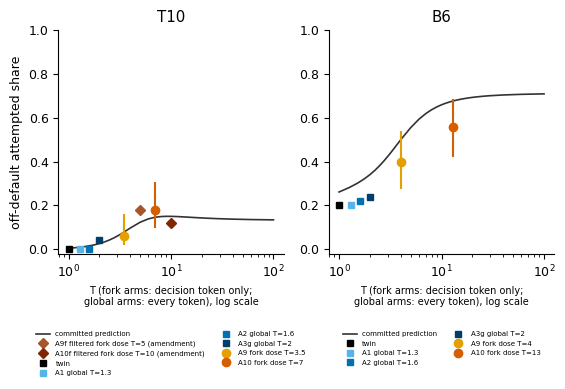

F1 ok


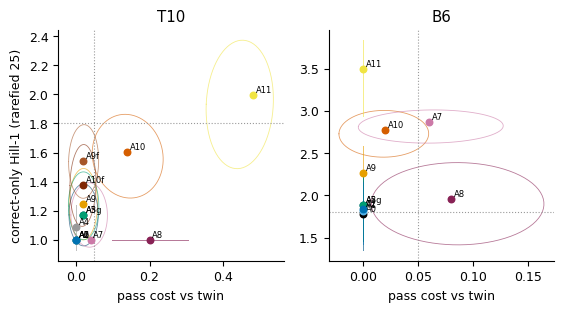

F2 ok


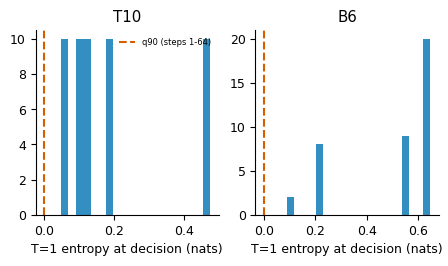

F3 ok


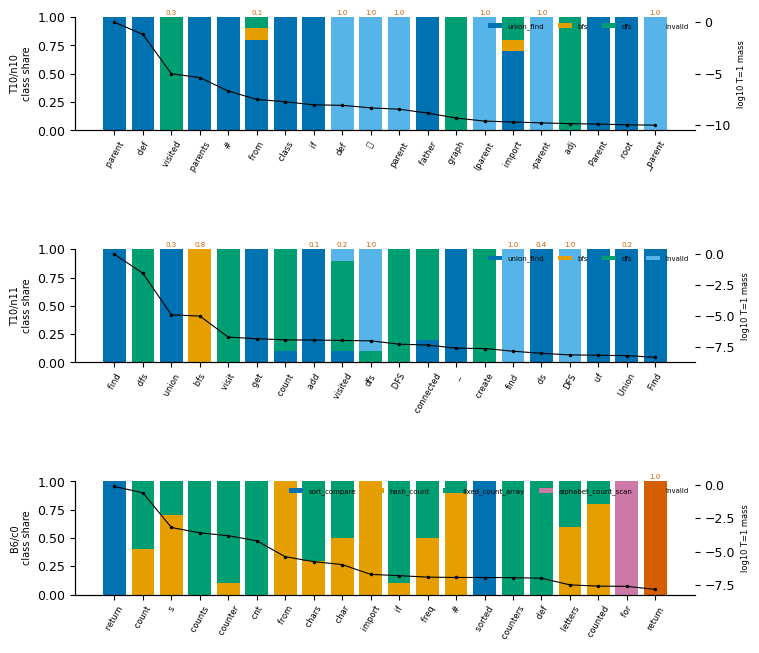

F4 ok


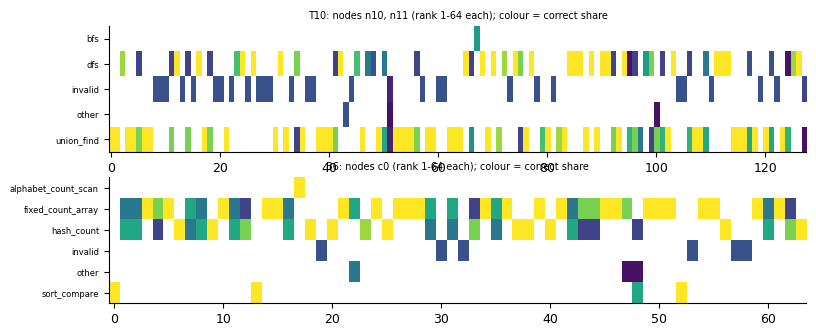

F5 ok


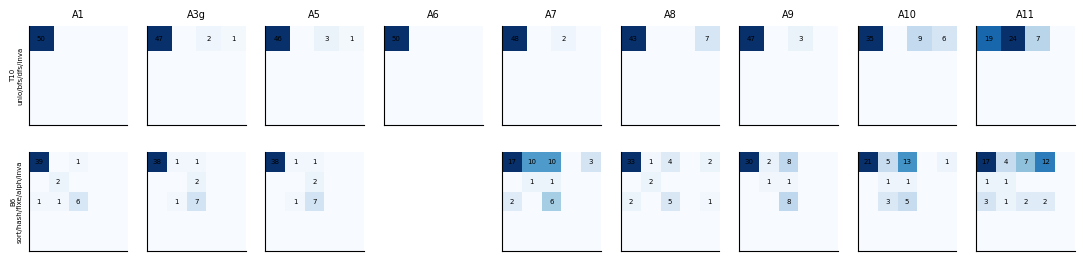

F7 ok


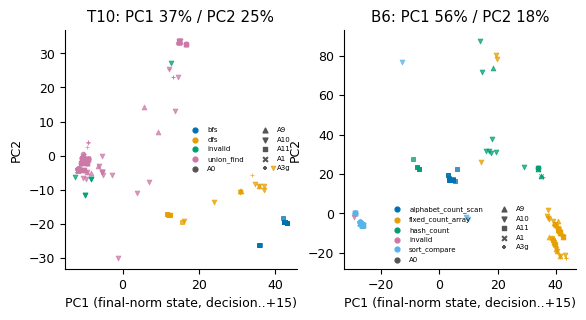

F8 ok


{
 "T10": {
  "explained_variance_pc1_pc2": [
   0.3679885268211365,
   0.248959481716156
  ],
  "n_states": 300,
  "nearest_centroid_agreement_fork_dosed": 0.9042553191489362,
  "n_fork_dosed_scored": 94,
  "centroid_classes": [
   "bfs",
   "dfs",
   "union_find"
  ]
 },
 "B6": {
  "explained_variance_pc1_pc2": [
   0.5634384751319885,
   0.1798793375492096
  ],
  "n_states": 233,
  "nearest_centroid_agreement_fork_dosed": 0.8311688311688312,
  "n_fork_dosed_scored": 77,
  "centroid_classes": [
   "alphabet_count_scan",
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ]
 }
}


In [29]:
def main() -> None:
    c1 = read_json(PRED_DIR / "commit1_dose_table.json")
    data = AK.load_rows()
    cells = read_json(RESULTS_DIR / "k1_cells.json") if (RESULTS_DIR / "k1_cells.json").exists() else {}
    hr = read_json(RESULTS_DIR / "hr.json") if (RESULTS_DIR / "hr.json").exists() else None
    loc = read_json(RESULTS_DIR / "locator.json") if (RESULTS_DIR / "locator.json").exists() else None
    geo = {}
    for name, fn in (("F1", lambda: f1(c1, cells)), ("F2", lambda: f2(data, cells)), ("F3", lambda: f3(c1, data)),
                     ("F4", lambda: f4(c1)), ("F5", lambda: f5(hr)), ("F7", lambda: f7(data)),   # F6: locator, not in the demo
                     ("F8", lambda: f8(data))):
        try:
            r = fn()
            if name == "F8":
                geo = r or {}
            print(name, "ok", flush=True)
        except Exception as e:  # noqa: BLE001 - a failing figure is reported, the others still render
            import traceback
            traceback.print_exc()
            print(name, "FAILED", e, flush=True)
    write_json(RESULTS_DIR / "geometry_f8.json", geo)


main()
print(json.dumps(read_json(RESULTS_DIR / "geometry_f8.json"), indent=1))

## 13. Results: does the notebook reproduce the shipped numbers?

The table compares every headline quantity recomputed above for T10 and B6 with the numbers shipped in the artifact
(`predictions/commit1_dose_table.json`, `predictions/commit3_amendment.json`, `results/k1_cells.json`,
`k1_verdict.json`, `amendment.json`, `hr.json`, `geometry_f8.json`). The bootstrap rows match only at the original
`N_BOOT = 2000`.

In [30]:
ref = data["reference_results"]
kv, kc = read_json(RESULTS_DIR / "k1_verdict.json"), read_json(RESULTS_DIR / "k1_cells.json")
amd, hrr = read_json(RESULTS_DIR / "amendment.json"), read_json(RESULTS_DIR / "hr.json")
geo, c3 = read_json(RESULTS_DIR / "geometry_f8.json"), read_json(PRED_DIR / "commit3_amendment.json")


def same(a, b, tol=1e-9):
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k], tol) for k in a)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return abs(a - b) <= tol
    return a == b


def short(x):
    if isinstance(x, float):
        return f"{x:.4g}"
    if isinstance(x, dict):
        return "{" + ", ".join(f"{k}: {short(y)}" for k, y in x.items()) + "}"
    if isinstance(x, (list, tuple)):
        return "[" + ", ".join(short(y) for y in x) + "]"
    return str(x)


checks = []
def check(name, mine, shipped, note=""):
    checks.append({"quantity": name, "recomputed": short(mine), "shipped": short(shipped),
                   "match": same(mine, shipped), "note": note})


CELL_KEYS = ["n", "attempted", "correct", "pass_rate", "hill1_correct_r25", "pass_cost", "pass_cost_ci95",
             "mcnemar_pass", "changed_decision", "breakage", "reversion", "label_flips_vs_twin",
             "byte_identical_to_twin", "reached_decision", "phrasing_clusters"]
for u in DEMO_UNITS:
    e, r = c1_table["units"][u], ref["commit1"][u]
    check(f"{u}: committed doses d1 / d2", [e["dose"]["d1"], e["dose"]["d2"]], [r["dose"]["d1"], r["dose"]["d2"]])
    check(f"{u}: composed prediction, d2 attempted shares", e["arms"]["A10"]["attempted"], r["arms"]["A10"]["attempted"])
    check(f"{u}: per-slot replay, d2 attempted shares", e["arms"]["A10"]["replay"]["attempted"],
          r["arms"]["A10"]["replay_attempted"])
    check(f"{u}: K1(a) MAE / replay MAE", [kv["K1a"]["per_unit"][u]["mae"], kv["K1a"]["per_unit"][u]["mae_replay"]],
          [ref["k1_verdict"]["K1a"][u]["mae"], ref["k1_verdict"]["K1a"][u]["mae_replay"]])
    n_ok = sum(same(kc[u][a][k], ref["k1_cells"][u][a][k]) for a in kc[u] for k in CELL_KEYS)
    n_all = len(kc[u]) * len(CELL_KEYS)
    check(f"{u}: K1 cell measures identical ({len(kc[u])} arms x {len(CELL_KEYS)})", f"{n_ok}/{n_all}", f"{n_all}/{n_all}")
    for a in ("A0", "A3g", "A9", "A10", "A11"):
        c, rc = kc[u][a], ref["k1_cells"][u][a]
        check(f"{u} {a}: pass rate / correct Hill-1", [c["pass_rate"], c["hill1_correct_r25"]],
              [rc["pass_rate"], rc["hill1_correct_r25"]])
    bs, rbs = kv["K1b"]["per_unit"][u]["bootstrap"]["best_comparator"], ref["k1_verdict"]["K1b"][u]["bootstrap"]["best_comparator"]
    check(f"{u}: K1(b) best fork - best comparator (mean, 97.5% LB, p)", [bs["mean_diff"], bs["lb_97_5"], bs["p_one_sided"]],
          [rbs["mean_diff"], rbs["lb_97_5"], rbs["p_one_sided"]], f"bootstrap, N_BOOT = {N_BOOT}")
check("T10: secondary exact McNemar, fork d2 vs global T 2.0", kv["secondary_mcnemar_A10_vs_A3g"]["T10"],
      ref["k1_verdict"]["secondary_mcnemar_A10_vs_A3g"]["T10"])
check("primary p (IUT over validated collapsed units = T10)", kv["primary_p_IUT"], ref["k1_verdict"]["primary_p_IUT"],
      f"bootstrap, N_BOOT = {N_BOOT}")
check("T10 amendment: doses d1 / d2", [c3["units"]["T10"]["dose"]["d1"], c3["units"]["T10"]["dose"]["d2"]],
      [ref["commit3_amendment"]["T10"]["dose"]["d1"], ref["commit3_amendment"]["T10"]["dose"]["d2"]])
for a in ("A9f", "A10f"):
    c, rc = amd["units"]["T10"]["cells"][a], ref["amendment"]["T10"]["cells"][a]
    check(f"T10 amendment {a}: pass rate / correct Hill-1 / pass cost",
          [c["pass_rate"], c["hill1_correct_r25"], c["pass_cost"]], [rc["pass_rate"], rc["hill1_correct_r25"], rc["pass_cost"]])
check("T10 amendment: filtered vs global T (bootstrap p)", amd["units"]["T10"]["bootstrap_vs"]["global_T"]["p_one_sided"],
      ref["amendment"]["T10"]["bootstrap_vs"]["global_T"]["p_one_sided"], f"bootstrap, N_BOOT = {N_BOOT}")
for u in DEMO_UNITS:
    x, rx = hrr["units"][u], ref["hr"][u]
    check(f"{u}: HR-only ideas", x["HR_only"], rx["HR_only"])
    check(f"{u}: T=1 mass of the HR-only idea", [x["reachability"][i]["m_T1"] for i in x["HR_only"]],
          [rx["reachability"][i]["m_T1"] for i in rx["HR_only"]])
    check(f"{u}: F8 nearest-centroid agreement (fork-dosed slots, n)",
          [geo[u]["nearest_centroid_agreement_fork_dosed"], geo[u]["n_fork_dosed_scored"]],
          [ref["geometry_f8"][u]["nearest_centroid_agreement_fork_dosed"], ref["geometry_f8"][u]["n_fork_dosed_scored"]])
pd.set_option("display.max_colwidth", 90)
tab = pd.DataFrame(checks)
display(tab)
boot = tab["note"].str.startswith("bootstrap")
print(f"{int(tab['match'].sum())}/{len(tab)} quantities match the shipped results "
      f"({int(tab.loc[~boot, 'match'].sum())}/{int((~boot).sum())} non-bootstrap; "
      f"{int(tab.loc[boot, 'match'].sum())}/{int(boot.sum())} bootstrap at N_BOOT = {N_BOOT}).")

,quantity,recomputed,shipped,match,note
0,T10: committed doses d1 / d2,"[3.5, 7]","[3.5, 7]",True,
1,"T10: composed prediction, d2 attempted shares","{union_find: 0.7161, bfs: 0.01648, dfs: 0.1297, other: 0, invalid: 0.1378}","{union_find: 0.7161, bfs: 0.01648, dfs: 0.1297, other: 0, invalid: 0.1378}",True,
2,"T10: per-slot replay, d2 attempted shares","{union_find: 0.7401, bfs: 0.01822, dfs: 0.124, other: 0, invalid: 0.1177}","{union_find: 0.7401, bfs: 0.01822, dfs: 0.124, other: 0, invalid: 0.1177}",True,
3,T10: K1(a) MAE / replay MAE,"[0.01703, 0.01348]","[0.01703, 0.01348]",True,
4,T10: K1 cell measures identical (14 arms x 15),210/210,210/210,True,
5,T10 A0: pass rate / correct Hill-1,"[1, 1]","[1, 1]",True,
6,T10 A3g: pass rate / correct Hill-1,"[0.98, 1.17]","[0.98, 1.17]",True,
7,T10 A9: pass rate / correct Hill-1,"[0.98, 1.243]","[0.98, 1.243]",True,
8,T10 A10: pass rate / correct Hill-1,"[0.86, 1.602]","[0.86, 1.602]",True,
9,T10 A11: pass rate / correct Hill-1,"[0.52, 1.995]","[0.52, 1.995]",True,


34/34 quantities match the shipped results (30/30 non-bootstrap; 4/4 bootstrap at N_BOOT = 2000).


### Ideas vs phrasings: what each knob actually changes

The chart re-reads the K1 cells in the terms of the original question. Does a knob give **N programs of one idea in
different phrasings**, or **programs of different ideas**?

- Bars: the correct programs per idea (algorithm), out of 50 CRN slots.
- Black diamonds: the number of distinct *phrasings* among them. A phrasing is a component of identifier-normalised
  token 4-gram Jaccard ≥ 0.8, summed over ideas.
- Label above each bar: the correct Hill-1.

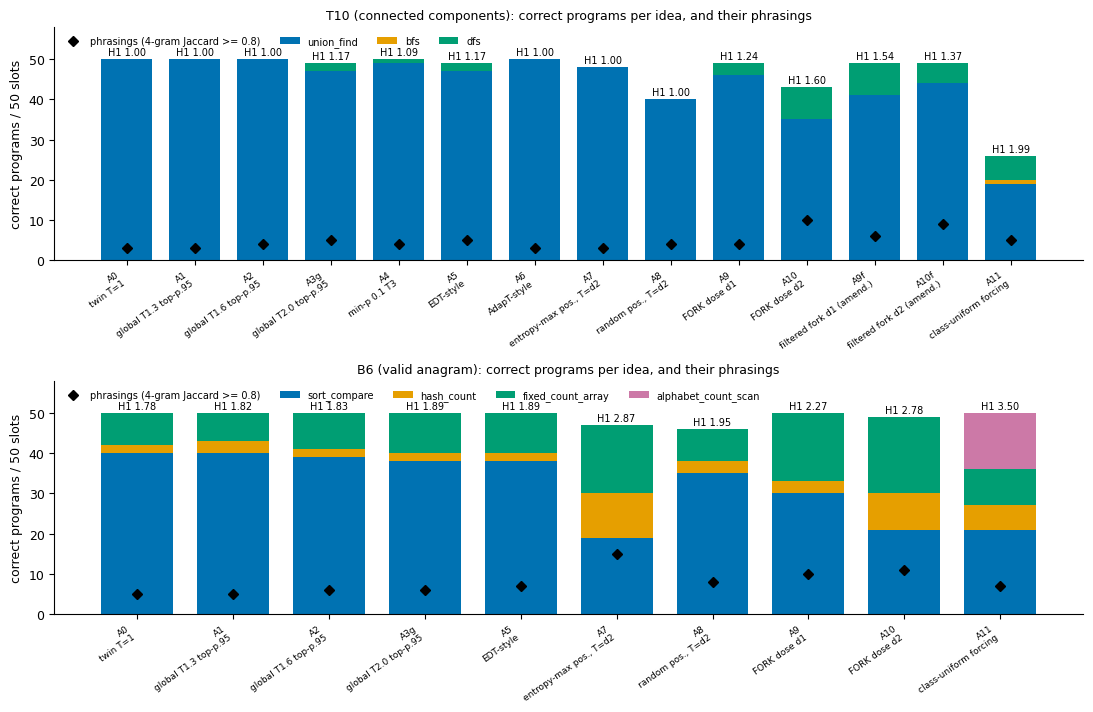

T10 {'A0': (1, 3), 'A1': (1, 3), 'A2': (1, 4), 'A3g': (2, 5), 'A4': (2, 4), 'A5': (2, 5), 'A6': (1, 3), 'A7': (1, 3), 'A8': (1, 4), 'A9': (2, 4), 'A10': (2, 10), 'A9f': (2, 6), 'A10f': (2, 9), 'A11': (3, 5)} -> (ideas, phrasings) among correct programs
B6 {'A0': (3, 5), 'A1': (3, 5), 'A2': (3, 6), 'A3g': (3, 6), 'A5': (3, 7), 'A7': (3, 15), 'A8': (3, 8), 'A9': (3, 10), 'A10': (3, 11), 'A11': (4, 7)} -> (ideas, phrasings) among correct programs


In [31]:
fig, axs = plt.subplots(len(DEMO_UNITS), 1, figsize=(11, 3.6 * len(DEMO_UNITS)), squeeze=False)
for ax, u in zip(axs[:, 0], DEMO_UNITS):
    cells = kc[u]
    arms = [a for a in ARM_ORDER if a in cells]
    ideas = [c for c in UNITS[u]["catalogue"] + ["other"] if any(cells[a]["correct_counts"].get(c) for a in arms)]
    x = np.arange(len(arms))
    bottom = np.zeros(len(arms))
    for ci, idea in enumerate(ideas):
        vals = np.array([cells[a]["correct_counts"].get(idea, 0) for a in arms], dtype=float)
        ax.bar(x, vals, bottom=bottom, color=PAL[ci % len(PAL)], width=0.75, label=idea)
        bottom += vals
    phr = [sum(p["0.8"] for p in cells[a]["phrasing_clusters"].values()) for a in arms]
    ax.plot(x, phr, "D", color="black", ms=5, label="phrasings (4-gram Jaccard >= 0.8)")
    for xi, a in zip(x, arms):
        h = cells[a]["hill1_correct_r25"]
        ax.text(xi, bottom[xi] + 1.0, "H1 n/a" if h is None else f"H1 {h:.2f}", ha="center", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{a}\n{ARM_DESC[a]}" for a in arms], fontsize=6.5, rotation=35, ha="right")
    ax.set_ylim(0, 58)
    ax.set_ylabel("correct programs / 50 slots")
    ax.set_title(f"{u} ({UNITS[u]['task']}): correct programs per idea, and their phrasings", fontsize=9)
    ax.legend(fontsize=7, frameon=False, ncol=len(ideas) + 1, loc="upper left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
plt.show()
for u in DEMO_UNITS:
    print(u, {a: (len([k for k, n in kc[u][a]["correct_counts"].items() if k != "invalid"]),
                  sum(p["0.8"] for p in kc[u][a]["phrasing_clusters"].values())) for a in ARM_ORDER if a in kc[u]},
          "-> (ideas, phrasings) among correct programs")

### Reading the results

- **The dial is predictable.** The committed composition of the decision token's logits and its token map gives each
  fork-dosed cell's algorithm mix to within an MAE of 0.017 on T10 and 0.047 on B6. The per-slot replay of each slot's
  own uniform gives it to within 0.013 and 0.031.
- **Where the alternative is already in play (B6), the dial sets the mix.**
  - Correct-program diversity rises from Hill-1 1.78 (twin) to 2.27 at d1 and 2.78 at d2, for a pass cost of 0 and 2
    points.
  - Global temperature and EDT stay at or below 1.89.
  - The paired bootstrap beats each comparator family run here (best-comparator lower bound +0.19, p = 0.008).
- **Where the model has collapsed (T10), the dial reaches what global temperature cannot, but only a little.**
  - DFS reaches 3/50 at d1 and 9/50 at d2, against 0-2/50 for global T (exact McNemar 7:1 vs T 2.0, p = 0.035).
  - Correct Hill-1 stays at 1.24 / 1.60, so the committed test (Hill-1 ≥ 1.8 at a cost ≤ 5 points) fails, with IUT
    p = 0.30.
  - d2 costs 14 pass points, because several of the top-20 candidates break the program. The amendment removes those
    candidates and brings the cost to 2 points, but the alternative holds only about 19% of the decision mass.
- **Ideas vs phrasings.**
  - Global temperature (≤ 2.0, with top-p 0.95) changes few programs. On T10 the correct programs keep 1-2 ideas in
    3-5 phrasings, and on B6 they keep 3 ideas in 5-6 phrasings, with the mix unchanged.
  - Dosing the decision token changes the idea mix. Because the whole continuation then changes, it also changes the
    phrasing: at d2, T10 has 2 ideas in 10 phrasings and B6 has 3 ideas in 11.
  - Class-uniform forcing reaches the most ideas: 3 on T10 and 4 on B6. On T10, however, forcing ` def bfs` mostly
    yields broken BFS programs.
- **No new algorithm.** Forcing every top-64 branch (HR) adds exactly one *known* idea per unit. Both are out of reach
  of the top-20 dial:

  | unit | HR-only idea | where | T = 1 mass | T = 1 samples to see it once | best fork-dose mass |
  |---|---|---|---|---|---|
  | T10 | BFS | rank 4 at `n11` | 5.4e-7 | about 1.8 x 10^6 | 0.005 |
  | B6 | alphabet-scan counter | rank 18 | 2.9e-8 | about 3.5 x 10^7 | 0.010 |
- **Activation geometry (F8).** In actual 4096-d final-norm activation space, the states after the decision token
  separate by algorithm: PC1 + PC2 explain 62% of the variance on T10 and 74% on B6. The fork-dosed slots sit nearest
  the class-forced centroid of their own algorithm (0.90 of 94 slots on T10, 0.83 of 77 on B6). So the dial moves the
  model between states it already has, not into new regions.

**Bottom line.** Temperature at the decision token is a precise, predictable dial between algorithms the model already
has, but it is not a source of new ones:

- Where an alternative is already in play (B6), it beats global temperature.
- Where the model has collapsed (T10), it reaches only a little further than global temperature.
- Nothing it reaches is novel.